In [1]:
import numpy as np
from invlap import invlap
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.linalg as sla
import time
from matplotlib.lines import Line2D

# General functions

$\phi_{i}(x,t) = \frac{1}{\sqrt{2\pi}h_x}\exp\left(-\frac{(x-x_i)^2}{h_x^2}\right)\frac{1}{\sqrt{2\pi}h_t}\exp\left(-\frac{(t-t_i)^2}{h_t^2}\right)$

$A \mathbf{u} = \mathbf{b}$

$A_{i,j} = \frac{2\lambda_{PDE}}{(x_1-x_0)T} \int_{x_0}^{x_1}\int_{0}^{T} R_{PDE,LH}(\phi_i,x,t)R_{PDE,LH}(\phi_j,x,t)  dt\, dx + \sum_k \frac{2\lambda_{BC,k}}{T} \int_{0}^{T} R_{BC,k,LH}(\phi_i,x,t) R_{BC,k,LH}(\phi_j,x,t) dt + \frac{2\lambda_{IC}}{x_1-x_0} \int_{0}^{T} R_{IC,LH}(\phi_i,x,t) R_{IC,LH}(\phi_j,x,t) dt $

$b_{i} = \frac{2\lambda_{PDE}}{(x_1-x_0)T} \int_{x_0}^{x_1}\int_{0}^{T} R_{PDE,LH}(\phi_i,x,t)R_{PDE,RH}(x,t)  dt\, dx + \sum_k \frac{2\lambda_{BC,k}}{T} \int_{0}^{T} R_{BC,k,LH}(\phi_i,x,t) R_{BC,k,RH}(x,t) dt + \frac{2\lambda_{IC}}{x_1-x_0} \int_{0}^{T} R_{IC,LH}(\phi_i,x,t) R_{IC,RH}(x,t) dt $

In [2]:
def compute_matrices_for_inverse(x_star,Nx,Nt,h_fac,extra_p,col_fac,
                                 data_x,data_t,
                                 PDE_funcs,R_funcs_rest,
                                 funcs_b,xt_stars):
    print(x_star,Nx,Nt,h_fac,extra_p)
    ## RBF centers
    deltax = 1/Nx
    deltat = 1/Nt
    hx = 1/Nx * h_fac
    ht = 1/Nt * h_fac
    xis = np.arange(-extra_p,Nx+extra_p+1)*deltax
    tis = np.arange(-extra_p,Nt+extra_p+1)*deltat
    Xis, Tis = np.meshgrid(xis, tis)
    Xis = Xis.flatten()
    Tis = Tis.flatten()
    
    # Colocation nodes
    x_evals = np.linspace(0,1,int(col_fac*Nx)+1)
    t_evals = np.linspace(0,1,int(col_fac*Nt)+1)
    ## Computing A
    wx = np.trapezoid(np.eye(len(x_evals)), x=x_evals, axis=1)  # weights on x
    wt = np.trapezoid(np.eye(len(t_evals)), x=t_evals, axis=1)  # weights on t
    
    # PDE_funcs = [phi_t_fun,phi_x_fun,phi_xx_fun]
    A_PDE = np.zeros((len(PDE_funcs),len(PDE_funcs),len(Xis),len(Xis)))
    for i in range(len(PDE_funcs)):
        R_PDE_eval_i = PDE_funcs[i](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
        R_PDE_eval_i = R_PDE_eval_i.reshape(t_evals.size * x_evals.size, len(Xis))
        for j in range(len(PDE_funcs)):
            R_PDE_eval_j = PDE_funcs[j](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
            R_PDE_eval_j = R_PDE_eval_j.reshape(t_evals.size * x_evals.size, len(Xis))
            # Full Kronecker weights on the flattened grid
            A_PDE[i,j] = (R_PDE_eval_i * (np.kron(wx, wt))[:, None]).T @ R_PDE_eval_j

    A_rest = np.zeros((len(Xis),len(Xis)))

    for R_fun in R_funcs_rest:
        R_eval = R_fun(x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
        if R_eval.shape[0]==1:
            A_rest += (R_eval.reshape(x_evals.size, len(Xis)) * (wx)[:, None]).T @ R_eval.reshape(x_evals.size, len(Xis))
        if R_eval.shape[1]==1:
            A_rest += (R_eval.reshape(t_evals.size, len(Xis)) * (wt)[:, None]).T @ R_eval.reshape(t_evals.size, len(Xis))

    phi_data_eval = phi_fun(data_x[:,None],data_t[:,None],Xis,Tis,hx,ht)
    
    b_PDE = np.zeros((len(PDE_funcs),len(Xis)))
    b_rest = np.zeros(len(Xis))
    
    for i in range(len(funcs_b)):
        if xt_stars[i]!=None:
            if i == 0:
                for j in range(len(PDE_funcs)):
                    if xt_stars[i][0]==None:
                        b_PDE[j] = funcs_b[i]*np.sum(PDE_funcs[j](x_evals[:,None],xt_stars[i][1],Xis,Tis,hx,ht)*(wx)[:, None],axis = 0)
                    elif xt_stars[i][1]==None:
                        b_PDE[j] = funcs_b[i]*np.sum(PDE_funcs[j](xt_stars[i][0],t_evals[:,None],Xis,Tis,hx,ht)*(wt)[:, None],axis = 0)
                    else:
                        b_PDE[j] += funcs_b[i]*PDE_funcs[j](xt_stars[i][0],xt_stars[i][1],Xis,Tis,hx,ht)
            if i>0:
                b_rest += funcs_b[i]*R_funcs_rest[i-1](xt_stars[i],xt_stars[i],Xis,Tis,hx,ht)
        else:
            if callable(funcs_b[i]):
                rhs = funcs_b[i](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
            if type(funcs_b[i]) == float or type(funcs_b[i]) == int:
                rhs = np.array([funcs_b[i]])[None,None,:]
            if i ==0:
                for j in range(len(PDE_funcs)):
                    R_PDE_eval_j = PDE_funcs[j](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
                    R_PDE_eval_j_mul = (rhs*R_PDE_eval_j).reshape(t_evals.size * x_evals.size, len(Xis))
                    b_PDE[j] = np.sum(R_PDE_eval_j_mul*(np.kron(wx, wt))[:, None],axis = 0)
            if i>0:
                b_rest += np.sum(wx[None,:,None]* wt[:,None,None]*rhs*R_funcs_rest[i-1](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht),axis = (0,1))
    
    return A_PDE,phi_data_eval,A_rest,b_PDE,b_rest

In [3]:
def no_grad_optimize_inverse(par, A_par_dep,A_par_indep,b_par_dep,b_par_indep,phi_data_eval,data_vals,epsilon = 10**-6):
    params = np.concatenate(([1.0],par))
    A = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + A_par_indep + np.eye(len(A_par_indep))*epsilon
    b = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + b_par_indep
    u = np.linalg.solve(A,b)
    
    u_loc = np.sum(u * phi_data_eval, axis=-1)

    e = u_loc - data_vals
    R = e@e
    
    return R

def grad_optimize_inverse(par, A_par_dep,A_par_indep,b_par_dep,b_par_indep,phi_data_eval,data_vals,epsilon = 10**-6):
    params = np.concatenate(([1.0],par))
    A = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + A_par_indep + np.eye(len(A_par_indep))*epsilon
    b = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + b_par_indep
    L = sla.cholesky(A, lower=True)
    u_aux = sla.solve_triangular(L, b, lower=True)
    u = sla.solve_triangular(L.T, u_aux, lower=False)
    
    u_loc = np.sum(u * phi_data_eval, axis=-1)

    e = u_loc - data_vals
    R = e@e

    dA_dp = np.array([(np.tensordot(A_par_dep[i], params, axes=(0, 0)) +
              np.tensordot(A_par_dep[:, i], params, axes=(0, 0))) for i in range(1,len(params))])
    
    db_dp = np.array([(np.tensordot(b_par_dep[i], params, axes=(0, 0)) +
              np.tensordot(b_par_dep[:, i], params, axes=(0, 0))) for i in range(1,len(params))])

    du_dp_aux = [sla.solve_triangular(L, db_dp[i]-dA_dp[i]@u, lower=True) for i in range(len(params)-1)]
    du_dp = np.array([sla.solve_triangular(L.T, du_dp_aux[i], lower=False) for i in range(len(params)-1)])

    de_dp = np.sum(du_dp[:,None,:] * phi_data_eval[None,:,:], axis=-1)

    dR_dp = 2*np.sum(e[None,:]*de_dp,axis=-1)
    return R, dR_dp

def grad_hess_optimize_inverse(par, A_par_dep,A_par_indep,b_par_dep,b_par_indep,phi_data_eval,data_vals,epsilon = 10**-6):
    params = np.concatenate(([1.0],par))
    A = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + A_par_indep + np.eye(len(A_par_indep))*epsilon
    b = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + b_par_indep
    L = sla.cholesky(A, lower=True)
    u_aux = sla.solve_triangular(L, b, lower=True)
    u = sla.solve_triangular(L.T, u_aux, lower=False)
    
    u_loc = np.sum(u * phi_data_eval, axis=-1)

    e = u_loc - data_vals
    R = e@e

    dA_dp = np.array([(np.tensordot(A_par_dep[i], params, axes=(0, 0)) +
              np.tensordot(A_par_dep[:, i], params, axes=(0, 0))) for i in range(1,len(params))])
    
    db_dp = np.array([(np.tensordot(b_par_dep[i], params, axes=(0, 0)) +
              np.tensordot(b_par_dep[:, i], params, axes=(0, 0))) for i in range(1,len(params))])

    du_dp_aux = [sla.solve_triangular(L, db_dp[i]-dA_dp[i]@u, lower=True) for i in range(len(params)-1)]
    du_dp = np.array([sla.solve_triangular(L.T, du_dp_aux[i], lower=False) for i in range(len(params)-1)])

    de_dp = np.sum(du_dp[:,None,:] * phi_data_eval[None,:,:], axis=-1)

    dR_dp = 2*np.sum(e[None,:]*de_dp,axis=-1)

    d2A_dp2 = np.array([[A_par_dep[i,j]+A_par_dep[j,i] for j in range(1,len(params))] for i in range(1,len(params))])
    d2b_dp2 = np.array([[b_par_dep[i,j]+b_par_dep[j,i] for j in range(1,len(params))] for i in range(1,len(params))])
    
    d2u_dp2_aux = [[sla.solve_triangular(L, d2b_dp2[i,j]-d2A_dp2[i,j]@u-dA_dp[i]@du_dp[j]-dA_dp[j]@du_dp[i], lower=True) for j in range(len(params)-1)] for i in range(len(params)-1)]
    d2u_dp2 = np.array([[sla.solve_triangular(L.T, d2u_dp2_aux[i][j], lower=False) for j in range(len(params)-1)] for i in range(len(params)-1)])

    d2e_dp2 = np.sum(d2u_dp2[:,:,None,:] * phi_data_eval[None,None,:,:], axis=-1)

    d2R_dp2 = 2* (np.einsum("ik,jk->ij", de_dp, de_dp) + np.sum(e[None,None,:] * d2e_dp2, axis=-1))
    
    return R, dR_dp, d2R_dp2

In [4]:
import sympy as sp

x, t = sp.symbols('x t', real=True)
xi, ti = sp.symbols('x_i t_i', real=True)  # center of basis φ
hx, ht = sp.symbols('h_x h_t', positive=True, real=True)
x0, t0 = sp.symbols('x_0 t_0', real=True)

phi = (1/sp.sqrt(2*sp.pi)/hx) * sp.exp(-(x - xi)**2/(2*hx**2)) \
    * (1/sp.sqrt(2*sp.pi)/ht) * sp.exp(-(t - ti)**2/(2*ht**2))

phi_t = sp.diff(phi, t)
phi_x = sp.diff(phi, x)
phi_xx = sp.diff(phi, x, 2)



phi_fun = sp.lambdify((x,t,xi,ti,hx,ht), phi, "numpy")
phi_t_fun = sp.lambdify((x,t,xi,ti,hx,ht), phi_t, "numpy")
phi_x_fun = sp.lambdify((x,t,xi,ti,hx,ht), phi_x, "numpy")
phi_xx_fun = sp.lambdify((x,t,xi,ti,hx,ht), phi_xx, "numpy")

zero = sp.lambdify((x,t,xi,ti,hx,ht), 0.0, "numpy")

phi_fun_minus = sp.lambdify((x,t,xi,ti,hx,ht), -phi, "numpy")
phi_t_fun_minus = sp.lambdify((x,t,xi,ti,hx,ht), -phi_t, "numpy")
phi_x_fun_minus = sp.lambdify((x,t,xi,ti,hx,ht), -phi_x, "numpy")
phi_xx_fun_minus = sp.lambdify((x,t,xi,ti,hx,ht), -phi_xx, "numpy")

R_IC_dirich = phi.subs(t, t0)
R_BC_dirich = phi.subs(x, x0)

R_IC_dirich_fun = sp.lambdify((x,t,xi,ti,hx,ht,t0), R_IC_dirich, "numpy")
R_BC_dirich_fun = sp.lambdify((x,t,xi,ti,hx,ht,x0), R_BC_dirich, "numpy")

# Problem 1

In [5]:
v, D = sp.symbols('v D', real=True)  # PDE parameters (velocity, diffusion)

R_PDE = phi_t + v * phi_x - D * phi_xx
# ---------------------------------------------------------
# Lambdify for NumPy
# ---------------------------------------------------------
R_PDE_fun = sp.lambdify((x,t,xi,ti,hx,ht,v,D), R_PDE, "numpy")



In [6]:
def ADE(x,t,v,D,sigma0 = 0.0):
    if sigma0==0.0:
        return np.where(t>0,1/np.sqrt(2*np.pi*(sigma0**2+2*D*t))*np.exp(-(x-v*t)**2/(2*(sigma0**2+2*D*t))),np.zeros_like(x))
    else:
        return 1/np.sqrt(2*np.pi*(sigma0**2+2*D*t))*np.exp(-(x-v*t)**2/(2*(sigma0**2+2*D*t)))

$R_{PDE,LH}(u,x,t) = \frac{\partial u}{\partial t} + v \frac{\partial u}{\partial x} - D \frac{\partial^2 u}{\partial x^2}; \quad R_{PDE,RH}(x,t) = 0; \quad x\in (0,1),\; t \in (0,1)$

$R_{IC,LH}(u,x) = u(t=0); \quad R_{IC,LH}(x) = \delta(x - x^*);$

$R_{LBC,RH}(u,x,t) = u(x = - x_0)$

$R_{LBC}(u,x,t) = u(x = - x_1)$

In [7]:
from time import time

In [8]:
def RBF_RLS_ADE_IPR(v_,D_,x_star,t0_,Nx,Nt,h_fac,extra_p,col_fac,lambda_IC,sigma0_ = 0.0,reg = 10**-6, return_condition = False):
    start = time()
    print(', '.join([i+'='+format(j,'.3g') for i,j in zip(['v','D','x*','t0','Nx','Nt','hfac','extra_p','col_fac','reg'],[v_,D_,x_star,t0_,Nx,Nt,h_fac,extra_p,col_fac,reg])]))
    ## RBF centers
    deltax = 1/Nx
    deltat = 1/Nt
    hx = 1/Nx * h_fac
    ht = 1/Nt * h_fac
    xis = np.arange(-extra_p,Nx+extra_p+1)*deltax
    tis = np.arange(-extra_p,Nt+extra_p+1)*deltat
    Xis, Tis = np.meshgrid(xis, tis)
    Xis = Xis.flatten()
    Tis = Tis.flatten()
    
    # Colocation nodes
    x_evals = np.linspace(0,1,int(col_fac*Nx)+1)
    t_evals = np.linspace(0,1,int(col_fac*Nt)+1)
    ## Computing A
    wx = np.trapezoid(np.eye(len(x_evals)), x=x_evals, axis=1)  # weights on x
    wt = np.trapezoid(np.eye(len(t_evals)), x=t_evals, axis=1)  # weights on t
    R_PDE_eval = R_PDE_fun(x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht,v_,D_)
    R_PDE_eval = R_PDE_eval.reshape(t_evals.size * x_evals.size, len(Xis))
    # Full Kronecker weights on the flattened grid
    A_PDE = (R_PDE_eval * (np.kron(wx, wt))[:, None]).T @ R_PDE_eval
    
    R_IC_eval = R_IC_dirich_fun(x_evals[:,None],t_evals[:,None],Xis,Tis,hx,ht,t0_)
    A_IC = (R_IC_eval * (wx)[:, None]).T @ R_IC_eval
    
    R_BC0_eval = R_BC_dirich_fun(x_evals[:,None],t_evals[:,None],Xis,Tis,hx,ht,0.0)
    A_BC0 = (R_BC0_eval * (wt)[:, None]).T @ R_BC0_eval
    
    R_BC1_eval = R_BC_dirich_fun(x_evals[:,None],t_evals[:,None],Xis,Tis,hx,ht,1.0)
    A_BC1 = (R_BC1_eval * (wt)[:, None]).T @ R_BC1_eval
    
    A = A_PDE+lambda_IC(t0_)*A_IC+A_BC0+A_BC1
    
    # Determine b
    if t0_ == 0.0 and sigma0_ == 0.0:
        b = lambda_IC(t0_)*R_IC_dirich_fun(x_star,t_evals[:,None],Xis,Tis,hx,ht,t0_)
    else:
        b = lambda_IC(t0_)*np.trapezoid(R_IC_eval*ADE(x_evals-x_star,t0_,v_,D_,sigma0_)[:,None],x = x_evals,axis = 0)
    interm = time()
    u = np.linalg.solve(A+np.eye(len(A))*reg,b)
    end = time()
    if return_condition:
        return u, len(A),interm-start,end-interm,A.nbytes,R_PDE_eval.nbytes, np.linalg.cond(A)
    else:
        return u, len(A),interm-start,end-interm,A.nbytes,R_PDE_eval.nbytes

In [9]:
def RBF_RLS_2D_func_fit(u_func_true,Nx,Nt,h_fac,extra_p,col_fac):
    start = time()
    print(v_,D_,x_star,t0_,Nx,Nt,h_fac,extra_p)
    ## RBF centers
    deltax = 1/Nx
    deltat = 1/Nt
    hx = 1/Nx * h_fac
    ht = 1/Nt * h_fac
    xis = np.arange(-extra_p,Nx+extra_p+1)*deltax
    tis = np.arange(-extra_p,Nt+extra_p+1)*deltat
    Xis, Tis = np.meshgrid(xis, tis)
    Xis = Xis.flatten()
    Tis = Tis.flatten()
    
    # Colocation nodes
    x_evals = np.linspace(0,1,int(col_fac*Nx)+1)
    t_evals = np.linspace(0,1,int(col_fac*Nx)+1)
    ## Computing A
    wx = np.trapezoid(np.eye(len(x_evals)), x=x_evals, axis=1)  # weights on x
    wt = np.trapezoid(np.eye(len(t_evals)), x=t_evals, axis=1)  # weights on t
    R_phi_eval_ = phi_fun(x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
    R_phi_eval = R_phi_eval_.reshape(t_evals.size * x_evals.size, len(Xis))
    # Full Kronecker weights on the flattened grid
    A = (R_phi_eval * (np.kron(wx, wt))[:, None]).T @ R_phi_eval
    b = np.trapezoid(np.trapezoid(R_phi_eval_*u_func_true(x_evals[None,:],t_evals[:,None])[:,:,None],x = t_evals,axis = 0),x = x_evals,axis = 0)
    u = np.linalg.solve(A+np.eye(len(A))*10**-6,b)
    print(time()-start)
    return u

In [10]:
%%time
v_,D_ = 0.7,0.0008
x_star = 0.1
t0_ = 0.0
Nxs = np.arange(30,81,10)
h_facs = np.arange(1.1,1.91,0.2)
extra_ps = np.arange(4)
col_facs = [1.2,1.3]
lambda_IC = lambda t0_: 10**(5*t0_)
regs = np.array([10**-8,10**-7,10**-6,10**-5,10**-4])
RBF_RLS_ADE_IPR_outputs = [[[[[RBF_RLS_ADE_IPR(v_,D_,x_star,t0_,Nx,int(Nx*v_),h_fac,extra_p,col_fac,lambda_IC,reg= reg) for Nx in Nxs]for h_fac in h_facs] for extra_p in extra_ps] for col_fac in col_facs] for reg in regs]

v=0.7, D=0.0008, x*=0.1, t0=0, Nx=30, Nt=21, hfac=1.1, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=40, Nt=28, hfac=1.1, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=50, Nt=35, hfac=1.1, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=60, Nt=42, hfac=1.1, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=70, Nt=49, hfac=1.1, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=80, Nt=56, hfac=1.1, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=30, Nt=21, hfac=1.3, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=40, Nt=28, hfac=1.3, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=50, Nt=35, hfac=1.3, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=60, Nt=42, hfac=1.3, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=70, Nt=49, hfac=1.3, extra_p=0, col_fac=1.2, reg=1e-08
v=0.7, D=0.0008, x*=0

In [11]:
us = [[[[[out[0] for out in outs4] for outs4 in outs3] for outs3 in outs2] for outs2 in outs1] for outs1 in RBF_RLS_ADE_IPR_outputs]

In [12]:
N_evals = 200
x_evals,t_evals = np.linspace(0,1,N_evals+1),np.linspace(0,1,N_evals+1)
u_field_true = np.zeros((len(t_evals),len(x_evals)))
u_field_true[1:] = ADE(x_evals-x_star,t_evals[1:,None],v_,D_)

In [13]:
%%time
u_fields = np.array([[[[[np.sum(np.sum(u.reshape((int(Nx*v_)+2*extra_p+1,Nx+2*extra_p+1))
                            *phi_fun(x_evals[None,:,None,None],
                                     t_evals[:,None,None,None],
                                     (np.arange(-extra_p,Nx+extra_p+1)/Nx),
                                     (np.arange(-extra_p,int(Nx*v_)+extra_p+1)/int(Nx*v_))[:,None],
                                     h_fac/Nx,
                                     h_fac/int(Nx*v_)),axis = -1),axis = -1) for Nx,u in zip(Nxs,u_)]
             for h_fac,u_ in zip(h_facs,u__)] for extra_p,u__ in zip(extra_ps,u___)]
                      for col_fac,u___ in zip(col_facs,u____)] for reg,u____ in zip(regs,us)])

CPU times: total: 17min 12s
Wall time: 17min 28s


In [14]:
error_fields = u_fields-u_field_true
errors = np.sqrt(np.sum((error_fields[:,:,:,:,:,1:])**2,axis = (-2,-1))/(error_fields.shape[-1]*error_fields.shape[-2]))
eval_range_t1 = int(N_evals*0.9)
errors_t1 = np.sqrt(np.sum((error_fields[:,:,:,:,:,-eval_range_t1:])**2,axis = (-2,-1))/(error_fields.shape[-1]*error_fields.shape[-2]))

In [15]:
best_idx = np.unravel_index(np.argmin(errors), errors.shape)
best_idx_1 = np.unravel_index(np.argmin(errors_t1), errors.shape)
print(regs[best_idx[0]], col_facs[best_idx[1]], extra_ps[best_idx[2]], h_facs[best_idx[3]], Nxs[best_idx[4]])
print(regs[best_idx_1[0]], col_facs[best_idx_1[1]], extra_ps[best_idx_1[2]], h_facs[best_idx_1[3]], Nxs[best_idx_1[4]])

1e-07 1.3 2 1.3 80
0.0001 1.3 2 1.3 80


(np.float64(0.46859031345202906), 2)

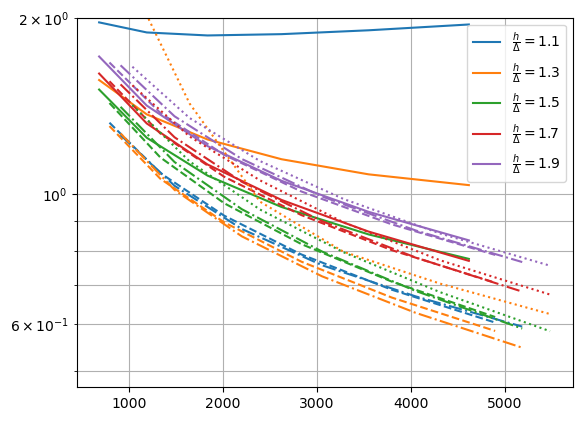

In [16]:
colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple']
linestyles = ['solid','dashed','dashdot','dotted',(0, (5, 10, 1, 10))]
k = best_idx[1]
for i,extra_p in enumerate(extra_ps):
    for j,h_fac in enumerate(h_facs):
        if i ==0:
            plt.semilogy((np.floor(Nxs*v_)+2*extra_p+1)*(Nxs+2*extra_p+1), errors[best_idx[0],k,i,j], c = colors[j], linestyle = linestyles[i], label = r'$\frac{h}{\Delta}=$'+str(round(h_fac,2)))
        else:
            plt.semilogy((np.floor(Nxs*v_)+2*extra_p+1)*(Nxs+2*extra_p+1), errors[best_idx[0],k,i,j], c = colors[j], linestyle = linestyles[i])
plt.legend()
plt.grid(which = 'both')
plt.ylim(None,2)

(np.float64(0.010915977691901156), 2)

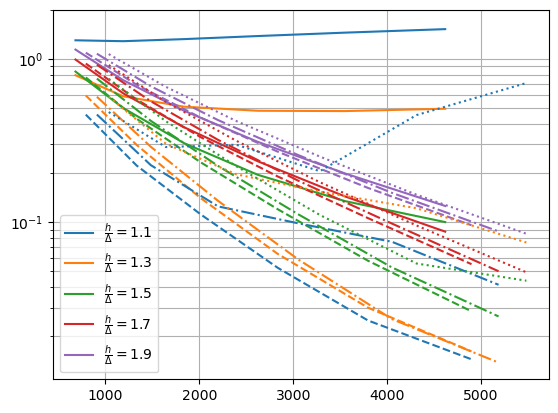

In [17]:
for i,extra_p in enumerate(extra_ps):
    for j,h_fac in enumerate(h_facs):
        if i ==0:
            plt.semilogy((np.floor(Nxs*v_)+2*extra_p+1)*(Nxs+2*extra_p+1), errors_t1[best_idx_1[0],k,i,j], c = colors[j], linestyle = linestyles[i], label = r'$\frac{h}{\Delta}=$'+str(round(h_fac,2)))
        else:
            plt.semilogy((np.floor(Nxs*v_)+2*extra_p+1)*(Nxs+2*extra_p+1), errors_t1[best_idx_1[0],k,i,j], c = colors[j], linestyle = linestyles[i])
plt.legend()
plt.grid(which = 'both')
plt.ylim(None,2)

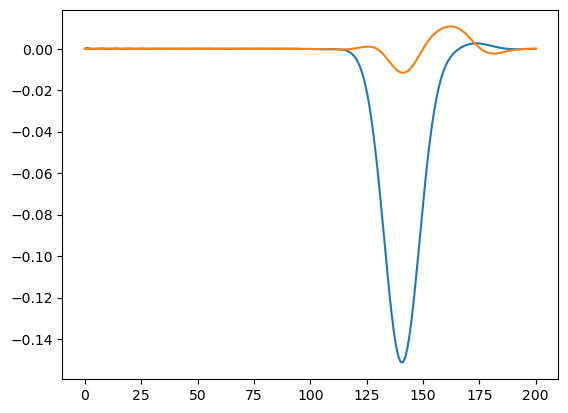

In [18]:
plt.plot(u_fields[*best_idx,-1]-u_field_true[-1])
plt.plot(u_fields[*best_idx_1,-1]-u_field_true[-1])

In [19]:
%%time
v_,D_ = 0.7,0.0008
x_star = 0.1
col_fac, extra_p, h_fac, Nx = col_facs[best_idx[1]], extra_ps[best_idx[2]], h_facs[best_idx[3]], Nxs[best_idx[4]]
u_real_fit = RBF_RLS_2D_func_fit(lambda x,t: ADE(x-x_star,t,v_,D_), Nx, int(Nx*v_), h_fac, extra_p, 1.5)

0.7 0.0008 0.1 0.0 80 56 1.3 2
10.090274333953857
CPU times: total: 38.8 s
Wall time: 10.1 s


In [20]:
u_field_real_fit = np.sum(np.sum(u_real_fit.reshape((int(Nx*v_)+2*extra_p+1,Nx+2*extra_p+1))
                            *phi_fun(x_evals[None,:,None,None],
                                     t_evals[:,None,None,None],
                                     (np.arange(-extra_p,Nx+extra_p+1)/Nx),
                                     (np.arange(-extra_p,int(Nx*v_)+extra_p+1)/int(Nx*v_))[:,None],
                                     h_fac/Nx,
                                     h_fac/int(Nx*v_)),axis = -1),axis = -1)

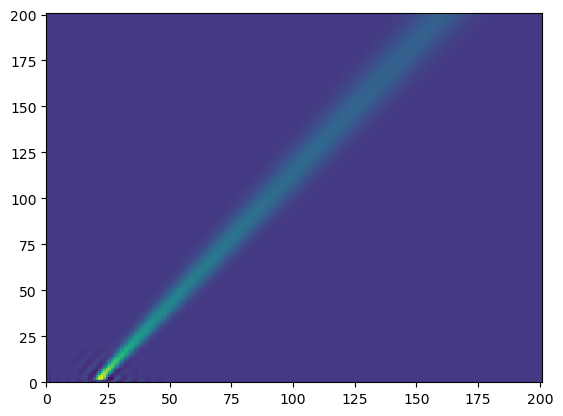

In [21]:
plt.pcolormesh(u_field_real_fit)

In [22]:
%%time
Nxs_ext = np.array([80,90,100,110,120,130,140])
outs_ext = [RBF_RLS_ADE_IPR(v_,D_,x_star,t0_,Nx,int(Nx*v_),h_facs[best_idx[3]],extra_ps[best_idx[2]],col_facs[best_idx[1]],lambda_IC,reg= regs[best_idx[0]]) for Nx in Nxs_ext]
us_ext = [i[0] for i in outs_ext]
u_fields_ext = np.array([np.sum(np.sum(u.reshape((int(Nx*v_)+2*extra_ps[best_idx[2]]+1,Nx+2*extra_ps[best_idx[2]]+1))
                            *phi_fun(x_evals[None,:,None,None],
                                     t_evals[:,None,None,None],
                                     (np.arange(-extra_ps[best_idx[2]],Nx+extra_ps[best_idx[2]]+1)/Nx),
                                     (np.arange(-extra_ps[best_idx[2]],int(Nx*v_)+extra_ps[best_idx[2]]+1)/int(Nx*v_))[:,None],
                                     h_facs[best_idx[3]]/Nx,
                                     h_facs[best_idx[3]]/int(Nx*v_)),axis = -1),axis = -1) for Nx,u in zip(Nxs_ext,us_ext)])
errors_ext = np.sqrt(np.sum((u_fields_ext[:,1:]-u_field_true[None,1:])**2,axis = (-2,-1))/(u_fields_ext.shape[-1]*u_fields_ext.shape[-2]))

v=0.7, D=0.0008, x*=0.1, t0=0, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=90, Nt=62, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=100, Nt=70, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=110, Nt=77, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=120, Nt=84, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=130, Nt=91, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=140, Nt=98, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
CPU times: total: 24min 21s
Wall time: 5min 57s


In [23]:
%%time
t0_s = np.linspace(0,1,6)[:-1]
lambda_IC = lambda t0_: 10**(5*t0_)
us_t0 = [RBF_RLS_ADE_IPR(v_,D_,x_star,t0_,Nx,int(Nx*v_),h_fac,extra_p,col_fac,lambda_IC)[0] for t0_ in t0_s]

v=0.7, D=0.0008, x*=0.1, t0=0, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-06
v=0.7, D=0.0008, x*=0.1, t0=0.2, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-06
v=0.7, D=0.0008, x*=0.1, t0=0.4, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-06
v=0.7, D=0.0008, x*=0.1, t0=0.6, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-06
v=0.7, D=0.0008, x*=0.1, t0=0.8, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-06
CPU times: total: 1min 57s
Wall time: 38.5 s


In [24]:
%%time
u_fields_t0 = np.array([np.sum(np.sum(u.reshape((int(Nx*v_)+2*extra_p+1,Nx+2*extra_p+1))
                            *phi_fun(x_evals[None,:,None,None],
                                     t_evals[:,None,None,None],
                                     (np.arange(-extra_p,Nx+extra_p+1)/Nx),
                                     (np.arange(-extra_p,int(Nx*v_)+extra_p+1)/int(Nx*v_))[:,None],
                                     h_fac/Nx,
                                     h_fac/int(Nx*v_)),axis = -1),axis = -1) for t0_,u in zip(t0_s,us_t0)])

CPU times: total: 8.03 s
Wall time: 8.17 s


In [25]:
%%time
sigma_ref = 1/Nxs[best_idx[4]]*h_facs[best_idx[3]]
sigma0_s = sigma_ref*np.array([0.25,0.5,1.0])
us_sigma0 = [RBF_RLS_ADE_IPR(v_,D_,x_star,0.0,Nx,int(Nx*v_),h_fac,extra_p,col_fac,lambda_IC,sigma0_)[0] for sigma0_ in sigma0_s]

v=0.7, D=0.0008, x*=0.1, t0=0, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-06
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-06
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-06
CPU times: total: 1min 6s
Wall time: 21.3 s


In [26]:
%%time
u_fields_sigma0 = np.array([np.sum(np.sum(u.reshape((int(Nx*v_)+2*extra_p+1,Nx+2*extra_p+1))
                            *phi_fun(x_evals[None,:,None,None],
                                     t_evals[:,None,None,None],
                                     (np.arange(-extra_p,Nx+extra_p+1)/Nx),
                                     (np.arange(-extra_p,int(Nx*v_)+extra_p+1)/int(Nx*v_))[:,None],
                                     h_fac/Nx,
                                     h_fac/int(Nx*v_)),axis = -1),axis = -1) for u in us_sigma0])

CPU times: total: 5 s
Wall time: 5.02 s


In [27]:
def scient_not(num,prec):
    exp = int(np.floor(np.log10(num)))
    mant = round(num/10**exp,prec)
    if prec == 0:
        mant = int(mant)
    return mant,exp

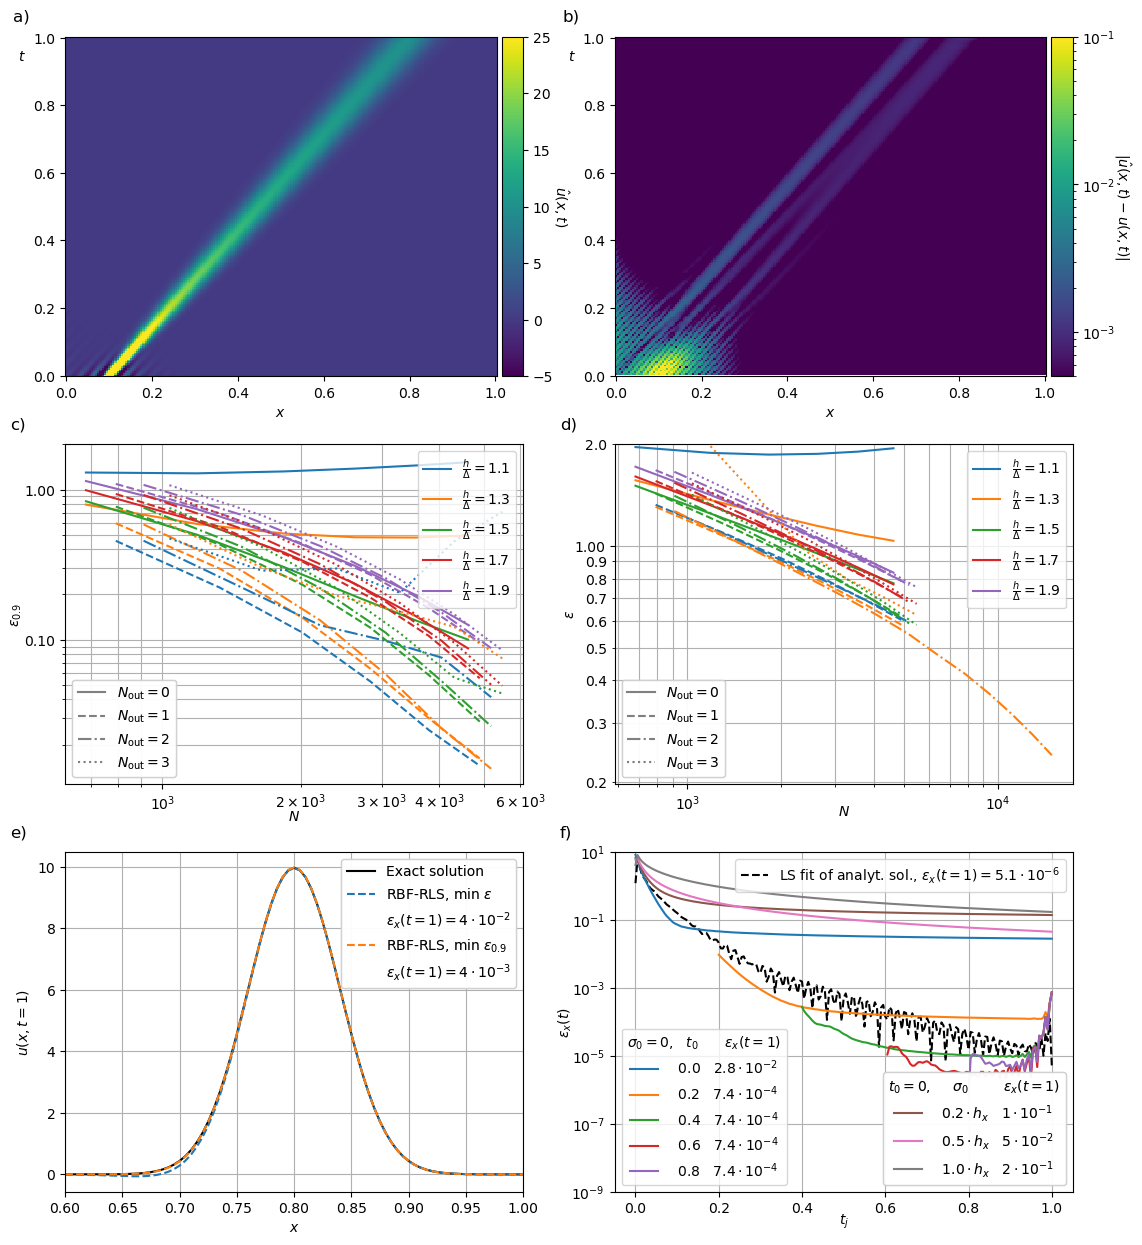

In [28]:
fig,axes  = plt.subplots(ncols = 2, nrows = 3 ,figsize=(13, 15))

from mpl_toolkits.axes_grid1 import make_axes_locatable
from math import floor
import matplotlib.ticker as mticker

im1 = axes[0][0].pcolormesh(x_evals,t_evals,u_fields[*best_idx_1],vmin=-5,vmax = 25)
divider = make_axes_locatable(axes[0][0])
cax = divider.append_axes('right', size='5%', pad=0.05)
cbar = fig.colorbar(im1, cax=cax, orientation='vertical')
cbar.ax.set_ylabel(r'$\hat{u}(x,t)$', rotation=270, labelpad=12)
axes[0][0].set_xlabel(r'$x$')
axes[0][0].set_ylabel(r'$t$',rotation = 0)
axes[0][0].yaxis.set_label_coords(-0.1,0.92)


from matplotlib.colors import LogNorm
im2 = axes[0][1].pcolormesh(x_evals,t_evals,np.abs((error_fields[*best_idx_1])/(np.max(u_field_true,axis = 1))[:,None]),norm = LogNorm(vmin = 0.0005,vmax = 0.1))
divider = make_axes_locatable(axes[0][1])
cax = divider.append_axes('right', size='5%', pad=0.05)
cbar = fig.colorbar(im2, cax=cax, orientation='vertical')
cbar.ax.set_ylabel(r'$|\hat{u}(x,t)-u(x,t)|$', rotation=270, labelpad=12)
axes[0][1].set_xlabel(r'$x$')
axes[0][1].set_ylabel(r'$t$',rotation = 0)
axes[0][1].yaxis.set_label_coords(-0.1,0.92)


k = best_idx_1[1]
lines = []
for i,extra_p in enumerate(extra_ps[:4]):
    for j,h_fac in enumerate(h_facs):
        if i ==0:
            line, = axes[1][0].loglog((np.floor(Nxs*v_)+2*extra_p+1)*(Nxs+2*extra_p+1), errors_t1[best_idx_1[0],k,i,j], c = colors[j], linestyle = linestyles[i], label = r'$\frac{h}{\Delta}=$'+str(round(h_fac,1)))
            lines.append(line)
        else:
            axes[1][0].loglog((np.floor(Nxs*v_)+2*extra_p+1)*(Nxs+2*extra_p+1), errors_t1[best_idx_1[0],k,i,j], c = colors[j], linestyle = linestyles[i])

first_legend = axes[1][0].legend(handles = lines,loc = 'upper right')
axes[1][0].add_artist(first_legend)
second_legend = axes[1][0].legend(handles = [Line2D([0,0],[0,0],c = 'gray', linestyle = linestyles[0],label = r'$N_{\text{out}}=0$'),
                                             Line2D([0,0],[0,0],c = 'gray', linestyle = linestyles[1],label = r'$N_{\text{out}}=1$'),
                                             Line2D([0,0],[0,0],c = 'gray', linestyle = linestyles[2],label = r'$N_{\text{out}}=2$'),
                                             Line2D([0,0],[0,0],c = 'gray', linestyle = linestyles[3],label = r'$N_{\text{out}}=3$')],
                                 loc = 'lower left')
axes[1][0].add_artist(second_legend)
axes[1][0].grid(which = 'both')
axes[1][0].set_xlabel(r'$N$', labelpad = -2)
axes[1][0].set_ylabel(r'$\varepsilon_{0.9}$', labelpad = 0)
axes[1][0].set_ylim(None,2)
from matplotlib.ticker import ScalarFormatter
axes[1][0].yaxis.set_major_formatter(ScalarFormatter())
# axes[1][0].yaxis.set_minor_formatter(ScalarFormatter())

k = best_idx[1]
lines = []
for i,extra_p in enumerate(extra_ps[:4]):
    for j,h_fac in enumerate(h_facs):
        if i ==0:
            line, = axes[1][1].loglog((np.floor(Nxs*v_)+2*extra_p+1)*(Nxs+2*extra_p+1), errors[best_idx[0],k,i,j], c = colors[j], linestyle = linestyles[i], label = r'$\frac{h}{\Delta}=$'+str(round(h_fac,1)))
            lines.append(line)
        else:
            axes[1][1].loglog((np.floor(Nxs*v_)+2*extra_p+1)*(Nxs+2*extra_p+1), errors[best_idx[0],k,i,j], c = colors[j], linestyle = linestyles[i])
        if all(np.array([k,i,j])  == best_idx[1:4]):
            axes[1][1].loglog((np.floor(Nxs_ext*v_)+2*extra_p+1)*(Nxs_ext+2*extra_p+1), errors_ext, c = colors[j], linestyle = linestyles[i])

first_legend = axes[1][1].legend(handles = lines,loc = 'upper right')
axes[1][1].add_artist(first_legend)
second_legend = axes[1][1].legend(handles = [Line2D([0,0],[0,0],c = 'gray', linestyle = linestyles[0],label = r'$N_{\text{out}}=0$'),
                                             Line2D([0,0],[0,0],c = 'gray', linestyle = linestyles[1],label = r'$N_{\text{out}}=1$'),
                                             Line2D([0,0],[0,0],c = 'gray', linestyle = linestyles[2],label = r'$N_{\text{out}}=2$'),
                                             Line2D([0,0],[0,0],c = 'gray', linestyle = linestyles[3],label = r'$N_{\text{out}}=3$')],
                                 loc = 'lower left')
axes[1][1].add_artist(second_legend)
axes[1][1].grid(which = 'both')
axes[1][1].set_xlabel(r'$N$', labelpad = -6)
axes[1][1].set_ylabel(r'$\varepsilon$', labelpad = -2)
axes[1][1].set_ylim(None,2)
from matplotlib.ticker import ScalarFormatter
axes[1][1].yaxis.set_major_formatter(ScalarFormatter())
axes[1][1].yaxis.set_minor_formatter(ScalarFormatter())

errors_t0 = [np.sqrt(np.sum(((u_field_ti-u_field_true))**2,axis = 1)/u_field_true.shape[1]) for u_field_ti in u_fields_t0]
errors_sigma0 = [np.sqrt(np.sum(((u_field_sigmai-u_field_true))**2,axis = 1)/u_field_true.shape[1]) for u_field_sigmai in u_fields_sigma0]
total_error_t0 = [np.sqrt(np.sum(((u_field_ti[1:]-u_field_true[1:]))**2)/u_field_true.size) for u_field_ti in u_fields_t0]
errors_sol_fit = np.sqrt(np.sum(((u_field_real_fit-u_field_true))**2,axis = 1)/u_field_true.shape[1])
total_error_t0_sol_fit = np.sqrt(np.sum(((u_field_real_fit[1:]-u_field_true[1:]))**2)/u_field_true.size)

line1, = axes[2][1].semilogy(t_evals,errors_sol_fit, c = 'k', linestyle = 'dashed',label=fr'LS fit of analyt. sol., $\varepsilon_{{x}}(t=1) = {scient_not(errors_sol_fit[-1],1)[0]}\cdot 10^{{{scient_not(errors_sol_fit[-1],1)[1]}}}$')
first_legend = axes[2][1].legend(handles=[line1], loc = 'upper right')
axes[2][1].add_artist(first_legend)
lines_second = []
for i in range(len(t0_s)):
    line_other, = axes[2][1].semilogy(t_evals[t_evals>=t0_s[i]],errors_t0[i][t_evals>=t0_s[i]],label=fr'  ${t0_s[i]:.1f}$   ${scient_not(errors_t0[i][-1],1)[0]}\cdot 10^{{{scient_not(errors_t0[i][-1],1)[1]}}}$')
    lines_second.append(line_other)

second_legend = axes[2][1].legend(handles=lines_second, title = r'$\sigma_0=0$,   $t_0$      $\varepsilon_{x}(t=1)$', loc = 'lower left')

lines_thrid = []

for i in range(len(sigma0_s)):
    line_other, = axes[2][1].semilogy(t_evals,errors_sigma0[i],
                                      label=fr'  ${sigma0_s[i]/sigma_ref:.1f}\cdot h_x$   ${scient_not(errors_sigma0[i][-1],0)[0]}\cdot 10^{{{scient_not(errors_sigma0[i][-1],0)[1]}}}$')
    lines_thrid.append(line_other)

third_legend = axes[2][1].legend(handles=lines_thrid, title = r'$t_0=0$,     $\sigma_0$        $\varepsilon_{x}(t=1)$', loc = 'lower right')
axes[2][1].add_artist(second_legend)
axes[2][1].add_artist(third_legend)
axes[2][1].grid()
axes[2][1].set_xlabel(r'$t_j$', labelpad = -2)
axes[2][1].set_ylabel(r'$\varepsilon_{x}(t)$', labelpad = -2)
axes[2][1].set_ylim(10**-(9),10.0)

plot_labels = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']

for ax, label in zip(axes.flat, plot_labels):
    ax.text(
        -0.12, 1.08, label,
        
        transform=ax.transAxes,
        fontsize=12,
        va='top', ha='left'
    )

error_x_best_idx = np.sqrt(np.sum(((u_fields[*best_idx]-u_field_true))**2,axis = 1)/u_field_true.shape[1])
error_x_best_idx_1 = np.sqrt(np.sum(((u_fields[*best_idx_1]-u_field_true))**2,axis = 1)/u_field_true.shape[1])

axes[2][0].plot(x_evals,u_field_true[-1], c = 'k')
axes[2][0].plot(x_evals,u_fields[*best_idx][-1],linestyle = 'dashed', c = 'tab:blue')
axes[2][0].plot(x_evals,u_fields[*best_idx_1][-1],linestyle = 'dashed', c = 'tab:orange')
legend = axes[2][0].legend(handles = [Line2D([0,0],[0,0],c = 'k', label = 'Exact solution'),
                                      Line2D([0,0],[0,0], c = 'tab:blue',linestyle = 'dashed', label = r'RBF-RLS, $\min\; \varepsilon$'),
                                    Line2D([0,0],[0,0],c = 'w', label = fr'$\varepsilon_{x}(t=1)={scient_not(error_x_best_idx[-1],0)[0]}\cdot 10^{{{scient_not(error_x_best_idx[-1],0)[1]}}}$'),
                                     Line2D([0,0],[0,0], c = 'tab:orange',linestyle = 'dashed', label = r'RBF-RLS, $\min\; \varepsilon_{0.9}$'),
                                      Line2D([0,0],[0,0],c = 'w', label = fr'$\varepsilon_{x}(t=1)={scient_not(error_x_best_idx_1[-1],0)[0]}\cdot 10^{{{scient_not(error_x_best_idx_1[-1],0)[1]}}}$')],
                                 loc = 'upper right')
axes[2][0].add_artist(legend)
axes[2][0].set_xlim(0.6,1.0)
axes[2][0].set_xlabel(r'$x$')
axes[2][0].set_ylabel(r'$u(x,t=1)$')
axes[2][0].grid()

\varepsilon-\varepsilon^* = 0.0033\cdot \left[\log(\epsilon_{\text{reg})-\log(\epsilon_{\text{reg}^*)\right]^2
\varepsilon-\varepsilon^* = 0.0805\cdot \left[N_{\text{out}}-N_{\text{out}}^*\right]^2
\varepsilon-\varepsilon^* = 0.717\cdot \left[\frac{h}{\Delta}-\frac{h}{\Delta}^*\right]^2
\varepsilon-\varepsilon^* = -0.315\cdot \left[\frac{N_\Omega}{N_x}-\frac{N_\Omega}{N_x}^*\right]
\varepsilon-\varepsilon^* = -0.00804\cdot \left[N_x-N_x^*\right]


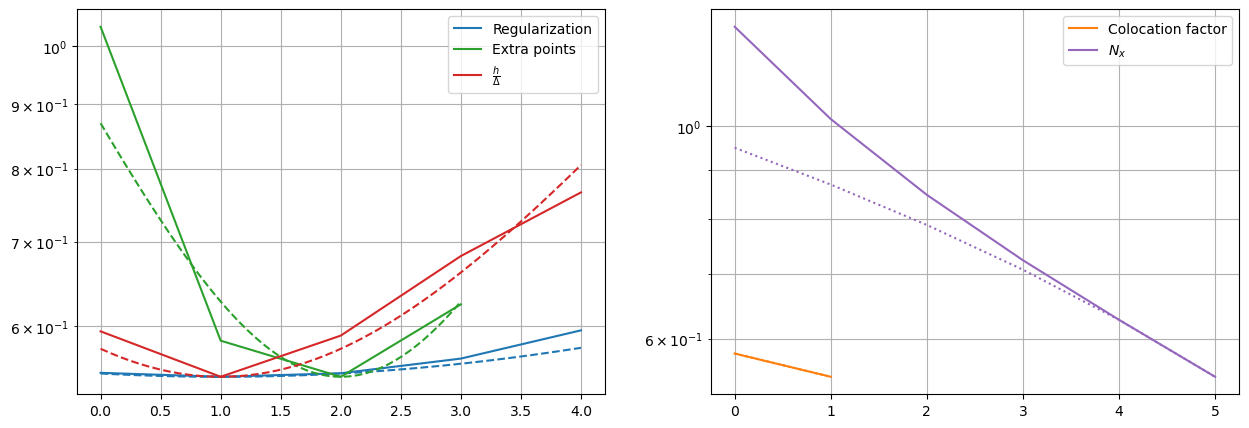

In [29]:
fig,axes = plt.subplots(ncols = 2, figsize = (15,5))
indep_params = [np.log10(regs), col_facs, extra_ps, h_facs, Nxs]
formulas_left = [r'\cdot \left[\log(\epsilon_{\text{reg})-\log(\epsilon_{\text{reg}^*)\right]',
                 r'\cdot \left[\frac{N_\Omega}{N_x}-\frac{N_\Omega}{N_x}^*\right]',
                 r'\cdot \left[N_{\text{out}}-N_{\text{out}}^*\right]',
                 r'\cdot \left[\frac{h}{\Delta}-\frac{h}{\Delta}^*\right]',
                 r'\cdot \left[N_x-N_x^*\right]']
for i in [0,2,3]:
    indep_var = indep_params[i]
    errors_i = errors[*best_idx[:i],:,*best_idx[i+1:]]
    quad_term = np.gradient(np.gradient(errors_i,indep_var),indep_var)[np.argmin(errors_i)]/2
    param_linspace = np.linspace(np.min(indep_params[i]),np.max(indep_params[i]))
    print(r'\varepsilon-\varepsilon^* = '+format(quad_term,'.3g')+formulas_left[i]+r'^2')
    axes[0].semilogy(errors_i, c = colors[i], label = ['Regularization','Colocation factor','Extra points',r'$\frac{h}{\Delta}$'][i])
    axes[0].semilogy(np.linspace(0,len(errors_i)-1),np.min(errors_i)+(np.linspace(0,len(errors_i)-1)-np.argmin(errors_i))**2
                 *np.gradient(np.gradient(errors_i,np.arange(len(errors_i))),np.arange(len(errors_i)))[np.argmin(errors_i)]/2, 
                 c = colors[i],linestyle = 'dashed')
    axes[0].grid(which = 'both')
axes[0].legend()

for i in [1,4]:
    indep_var = indep_params[i]
    errors_i = errors[*best_idx[:i],:,*best_idx[i+1:]]
    der_sensitiv = np.gradient(errors_i,indep_var)[np.argmin(errors_i)]
    print(r'\varepsilon-\varepsilon^* = '+format(der_sensitiv,'.3g')+formulas_left[i])
    axes[1].semilogy(errors_i, c = colors[i], label = ['Regularization','Colocation factor','Extra points',r'$\frac{h}{\Delta}$', r'$N_x$'][i])
    axes[1].semilogy(np.min(errors_i)+(np.arange(len(errors_i))-np.argmin(errors_i))*np.gradient(errors_i,np.arange(len(errors_i)))[np.argmin(errors_i)], c = colors[i],linestyle = 'dotted')
axes[1].grid(which = 'both')
axes[1].legend()

\varepsilon-\varepsilon^* = 0.0755\cdot \left[N_{\text{out}}-N_{\text{out}}^*\right]^2 0.096
\varepsilon-\varepsilon^* = 0.286\cdot \left[\frac{h}{\Delta}-\frac{h}{\Delta}^*\right]^2 0.049
\varepsilon-\varepsilon^* = -0.00805\cdot \left[\log(\epsilon_{\text{reg})-\log(\epsilon_{\text{reg}^*)\right] -0.086
\varepsilon-\varepsilon^* = -0.0387\cdot \left[\frac{N_\Omega}{N_x}-\frac{N_\Omega}{N_x}^*\right] -0.018
\varepsilon-\varepsilon^* = -0.00117\cdot \left[N_x-N_x^*\right] -0.59


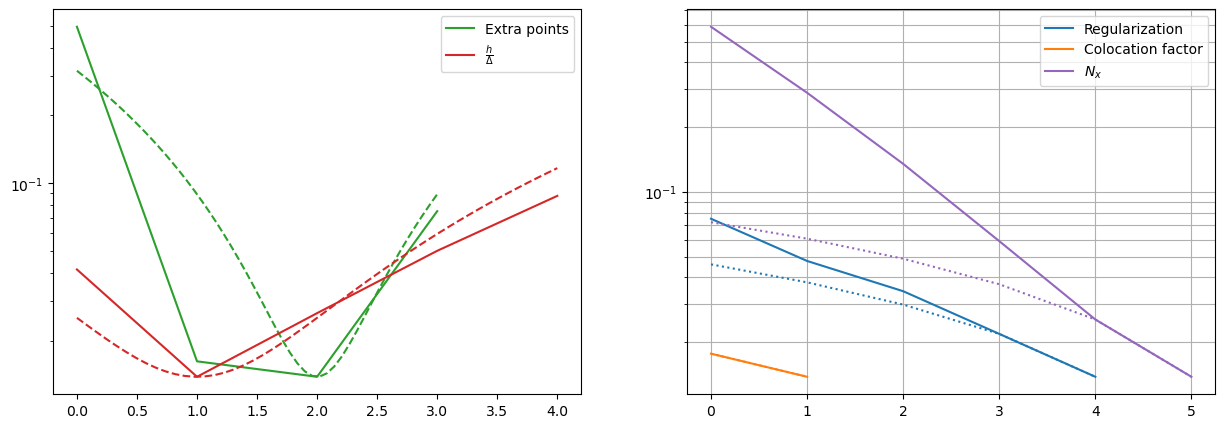

In [30]:
fig,axes = plt.subplots(ncols = 2, figsize = (15,5))
indep_params = [np.log10(regs), col_facs, extra_ps, h_facs, Nxs]
formulas_left = [r'\cdot \left[\log(\epsilon_{\text{reg})-\log(\epsilon_{\text{reg}^*)\right]',
                 r'\cdot \left[\frac{N_\Omega}{N_x}-\frac{N_\Omega}{N_x}^*\right]',
                 r'\cdot \left[N_{\text{out}}-N_{\text{out}}^*\right]',
                 r'\cdot \left[\frac{h}{\Delta}-\frac{h}{\Delta}^*\right]',
                 r'\cdot \left[N_x-N_x^*\right]']
for i in [2,3]:
    indep_var = indep_params[i]
    errors_i = errors_t1[*best_idx_1[:i],:,*best_idx_1[i+1:]]
    quad_term = np.gradient(np.gradient(errors_i,indep_var),indep_var)[np.argmin(errors_i)]/2
    param_linspace = np.linspace(np.min(indep_params[i]),np.max(indep_params[i]))
    print(r'\varepsilon-\varepsilon^* = '+format(quad_term,'.3g')+formulas_left[i]+r'^2',
          format(np.sqrt(0.05/(quad_term/np.min(errors_i))),'.2g'))
    axes[0].semilogy(errors_i, c = colors[i], label = ['Regularization','Colocation factor','Extra points',r'$\frac{h}{\Delta}$'][i])
    axes[0].semilogy(np.linspace(0,len(errors_i)-1),np.min(errors_i)+(np.linspace(0,len(errors_i)-1)-np.argmin(errors_i))**2
                 *np.gradient(np.gradient(errors_i,np.arange(len(errors_i))),np.arange(len(errors_i)))[np.argmin(errors_i)]/2, 
                 c = colors[i],linestyle = 'dashed')
    axes[0].grid(which = 'both')
axes[0].legend()

for i in [0,1,4]:
    indep_var = indep_params[i]
    errors_i = errors_t1[*best_idx_1[:i],:,*best_idx_1[i+1:]]
    der_sensitiv = np.gradient(errors_i,indep_var)[np.argmin(errors_i)]
    print(r'\varepsilon-\varepsilon^* = '+format(der_sensitiv,'.3g')+formulas_left[i],
          format(0.05/(der_sensitiv/np.min(errors_i)),'.2g'))
    axes[1].semilogy(errors_i, c = colors[i], label = ['Regularization','Colocation factor','Extra points',r'$\frac{h}{\Delta}$', r'$N_x$'][i])
    axes[1].semilogy(np.min(errors_i)+(np.arange(len(errors_i))-np.argmin(errors_i))*np.gradient(errors_i,np.arange(len(errors_i)))[np.argmin(errors_i)], c = colors[i],linestyle = 'dotted')
axes[1].grid(which = 'both')
axes[1].legend()

In [31]:
outs_Nx_ext = [RBF_RLS_ADE_IPR(v_,D_,x_star,t0_,Nx,int(Nx*v_),h_facs[best_idx[3]],extra_ps[best_idx[2]],col_facs[best_idx[1]],lambda_IC,reg= regs[best_idx[0]],return_condition = True) for Nx in np.unique(np.concatenate((Nxs,Nxs_ext)))]

v=0.7, D=0.0008, x*=0.1, t0=0, Nx=30, Nt=21, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=40, Nt=28, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=50, Nt=35, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=60, Nt=42, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=70, Nt=49, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=80, Nt=56, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=90, Nt=62, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=100, Nt=70, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=110, Nt=77, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=120, Nt=84, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, x*=0.1, t0=0, Nx=130, Nt=91, hfac=1.3, extra_p=2, col_fac=1.3, reg=1e-07
v=0.7, D=0.0008, 

In [32]:
for out in outs_Nx_ext:
    print(*[format(i/j,'.3g') for i,j in zip(out[1:],[1,1,1,10**6,10**6,1])])

910 0.0666 0.0221 6.62 8.15 5.1e+14
1.48e+03 0.186 0.0876 17.6 23.3 6.27e+14
2.2e+03 0.498 0.239 38.7 53.4 7.67e+14
3.06e+03 1.11 0.657 74.7 106 9.32e+14
4.05e+03 2.65 1.39 131 191 1.11e+15
5.18e+03 4.3 2.83 215 318 1.28e+15
6.36e+03 7.65 4.92 324 487 1.42e+15
7.88e+03 16.4 9.41 496 759 1.49e+15
9.43e+03 23.1 15.8 711 1.1e+03 1.62e+15
1.11e+04 37 10.7 990 1.54e+03 1.77e+15
1.3e+04 56.6 18.3 1.34e+03 2.1e+03 1.88e+15
1.49e+04 83.7 23.5 1.78e+03 2.8e+03 1.96e+15


## Inverse

In [33]:
%%time
v_,D_ = 0.7,0.0008
x_star = 0.1
reg, col_fac, extra_p, h_fac, Nx = regs[best_idx_1[0]], col_facs[best_idx_1[1]], extra_ps[best_idx_1[2]], h_facs[best_idx_1[3]], Nxs[best_idx_1[4]]
Nx = 80


data_x = np.linspace(0,1,50)
data_t = np.ones_like(data_x)
data_vals = ADE(data_x-x_star,data_t,v_,D_)

PDE_funcs = [phi_t_fun,phi_x_fun,lambda x, t, x_i, t_i, h_x, h_t:-phi_xx_fun(x, t, x_i, t_i, h_x, h_t)]
R_funcs_rest = [lambda x, t, x_i, t_i, h_x, h_t: R_IC_dirich_fun(x, t, x_i, t_i, h_x, h_t, 0.0),
                lambda x, t, x_i, t_i, h_x, h_t: R_BC_dirich_fun(x, t, x_i, t_i, h_x, h_t, 0.0),
                lambda x, t, x_i, t_i, h_x, h_t: R_BC_dirich_fun(x, t, x_i, t_i, h_x, h_t, 1.0)]
funcs_b = [0,1.0,0,0]
xt_stars = [None,x_star,None,None]

# A_PDE,phi_data_eval,A_rest,b = RBF_RLS_ADE_IPR_inv_matrices(x_star,Nx,int(Nx*v_),h_fac,extra_p,col_fac,data_x,data_t,PDE_funcs)
A_PDE,phi_data_eval,A_rest,b_PDE,b_rest = compute_matrices_for_inverse(x_star,Nx,int(Nx*v_),h_fac,extra_p,col_fac,
                                 data_x,data_t,
                                 PDE_funcs,R_funcs_rest,
                                 funcs_b,xt_stars)

0.1 80 56 1.3 2
CPU times: total: 2min 35s
Wall time: 30.6 s


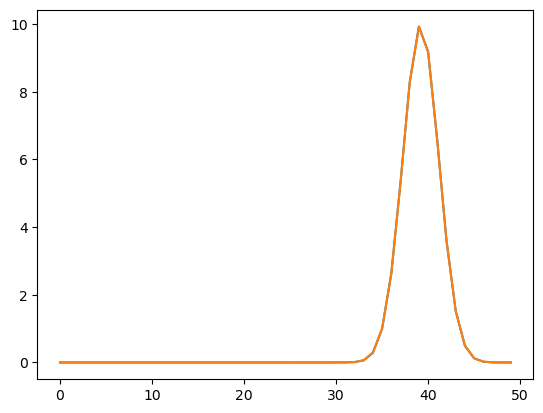

In [34]:
A = np.sum((np.array([1,v_,D_])*np.array([1,v_,D_])[:,None])[:,:,None,None]*A_PDE,axis = (0,1))+A_rest+ np.eye(len(A_rest))*reg
b = np.sum(np.array([1,v_,D_])[:,None]*b_PDE,axis = (0))+b_rest
u= np.linalg.solve(A,b)
u_loc = np.sum(u * phi_data_eval, axis=-1)
plt.plot(u_loc)
plt.plot(data_vals)

In [51]:
%%time
np.linalg.solve(A,b)
A_par_dep = A_PDE
b_par_dep = np.zeros((A_PDE.shape[:-1]))
b_par_dep[0] = b_PDE
A_par_indep = A_rest
b_par_indep = b_rest

CPU times: total: 3.02 s
Wall time: 3.39 s


In [53]:
%%time
no_grad_optimize_inverse(np.array([v_,D_]),A_par_dep, A_par_indep, b_par_dep, b_par_indep,phi_data_eval,data_vals)

CPU times: total: 4.05 s
Wall time: 3.12 s


np.float64(0.03886274656022675)

In [54]:
%%time
grad_hess_optimize_inverse(np.array([v_,D_]),A_par_dep, A_par_indep, b_par_dep, b_par_indep,phi_data_eval,data_vals)

CPU times: total: 8.2 s
Wall time: 4.35 s


(np.float64(0.03886681489645566),
 array([   51.94321183, -1112.78431446]),
 array([[ 2.16727459e+05, -1.71952855e+04],
        [-1.71952855e+04,  2.06006270e+08]]))

In [55]:
np.random.seed(0)
x0s =  [[v_*np.random.uniform(0.92,1.08),D_*2**np.random.uniform(-1,1)] for i in range(30)]

In [40]:
%%time
results_grad_hess = []
for x0 in x0s:
    def fgh(x):
        xt = tuple(x)  # makes it hashable
        if xt not in _cache:
            f, g, H = grad_hess_optimize_inverse(x,A_par_dep, A_par_indep, b_par_dep, b_par_indep,phi_data_eval,data_vals)  # your function
            _cache[xt] = (f, g, H)
        return _cache[xt]
    
    def fun(x):
        return fgh(x)[0]
    
    def grad(x):
        return fgh(x)[1]
    
    def hess(x):
        return fgh(x)[2]
    # Cache dictionary
    _cache = {}
    result_grad_hess = minimize(fun, x0, method='trust-constr', jac=grad, hess=hess)
    print(format(result_grad_hess.fun,'.5%'),
      *[format(abs(i),'.5%') for i in result_grad_hess.x/np.array([v_,D_])-1],
      format(np.linalg.norm(ADE(data_x-x_star,data_t,result_grad_hess.x[0],result_grad_hess.x[1])-data_vals)/np.sqrt(len(data_vals)),'.5%'))
    results_grad_hess.append(result_grad_hess)

2.96034% 0.03435% 0.68469% 1.35825%
2.96036% 0.03472% 0.68454% 1.36796%
2.96038% 0.03435% 0.68469% 1.35824%
2.96034% 0.03435% 0.68469% 1.35823%
2.96028% 0.03435% 0.68468% 1.35823%
2.96035% 0.03435% 0.68469% 1.35823%
2.96033% 0.03435% 0.68469% 1.35822%
2.96026% 0.03419% 0.68431% 1.35380%
2.96038% 0.03435% 0.68469% 1.35823%
2.96030% 0.03435% 0.68454% 1.35820%
2.96034% 0.03415% 0.68380% 1.35237%
2.96033% 0.03458% 0.68471% 1.36442%
2.96030% 0.03435% 0.68468% 1.35823%
2.96036% 0.03435% 0.68181% 1.35625%
2.96035% 0.03435% 0.68469% 1.35825%
2.96035% 0.03435% 0.68470% 1.35824%
2.96037% 0.03435% 0.68469% 1.35824%
2.96037% 0.03435% 0.68470% 1.35824%
2.96030% 0.03441% 0.68465% 1.35982%
2.96034% 0.03435% 0.68467% 1.35821%
2.96039% 0.03435% 0.68470% 1.35825%
2.96037% 0.03435% 0.68470% 1.35825%
2.96038% 0.03435% 0.68469% 1.35823%
2.96030% 0.03435% 0.68469% 1.35823%
2.96038% 0.03435% 0.68469% 1.35824%
2.96039% 0.03435% 0.68469% 1.35824%
2.96036% 0.03435% 0.68469% 1.35824%
2.96038% 0.03434% 0.68325% 1

In [41]:
np.mean([res.nfev for res in results_grad_hess])

np.float64(10.633333333333333)

In [62]:
np.mean([res.nfev for res in results_grad_hess])

np.float64(10.633333333333333)

In [63]:
np.set_printoptions(formatter={'float': lambda x: f"{x*100:.3f}%"})
print(np.percentile([(res.fun/len(data_vals))**(1/2) for res in results_grad_hess],[10,50,90]),
 *np.percentile([np.abs(res.x/np.array([v_,D_])-1) for res in results_grad_hess],[10,50,90],axis = 0).T,
 np.percentile([np.linalg.norm(ADE(data_x-x_star,data_t,*res.x)-data_vals)/np.sqrt(len(data_vals)) for res in results_grad_hess],[10,50,90],axis = 0))
np.set_printoptions(formatter=None)

[2.433% 2.433% 2.433%] [0.034% 0.034% 0.034%] [0.684% 0.685% 0.685%] [1.357% 1.358% 1.358%]


# Problem 3

In [65]:
v, D, beta, k = sp.symbols('v D \beta k', real=True)  # PDE parameters (velocity, diffusion)
x0, t0 = sp.symbols('x_0 t_0', real=True)

R_PDE_1_m = phi_t + v * phi_x - D * phi_xx + beta * k * phi
R_PDE_1_i = - beta * k * phi
R_PDE_2_m = - k * phi
R_PDE_2_i = phi_t + k * phi

R_IC_dirich = phi.subs(t, t0)
R_BC_dirich = phi.subs(x, x0)

R_PDE_1_m_fun = sp.lambdify((x,t,xi,ti,hx,ht,v,D,beta,k), R_PDE_1_m, "numpy")
R_PDE_1_i_fun = sp.lambdify((x,t,xi,ti,hx,ht,v,D,beta,k), R_PDE_1_i, "numpy")
R_PDE_2_m_fun = sp.lambdify((x,t,xi,ti,hx,ht,v,D,beta,k), R_PDE_2_m, "numpy")
R_PDE_2_i_fun = sp.lambdify((x,t,xi,ti,hx,ht,v,D,beta,k), R_PDE_2_i, "numpy")

R_IC_dirich_fun = sp.lambdify((x,t,xi,ti,hx,ht,t0), R_IC_dirich, "numpy")
R_BC_dirich_fun = sp.lambdify((x,t,xi,ti,hx,ht,x0), R_BC_dirich, "numpy")

In [66]:
%%time
M0_, v_,D_,beta_, k_ = 1.0, 0.7, 0.0008, 0.05, 10.0
x_star = 0.1
col_fac, extra_p, h_fac = 1.3, 2, 1.4
Nx = 50
Nt = int(Nx*v_)

deltax = 1 / Nx
deltat = 1 / Nt
hx = deltax * h_fac
ht = deltat * h_fac

xis = np.arange(-extra_p, Nx + extra_p + 1) * deltax
tis = np.arange(-extra_p, Nt + extra_p + 1) * deltat
Xis, Tis = np.meshgrid(xis, tis, indexing="xy")
Xis = Xis.flatten()
Tis = Tis.flatten()

# ======================================================
# Collocation grid
# ======================================================
x_evals = np.linspace(0, 1, int(col_fac * Nx) + 1)
t_evals = np.linspace(0, 1, int(col_fac * Nt) + 1)

wx = np.trapezoid(np.eye(len(x_evals)), x=x_evals, axis=1)
wt = np.trapezoid(np.eye(len(t_evals)), x=t_evals, axis=1)
W = np.kron(wx, wt)

A_IC = np.zeros((2*len(Xis),2*len(Xis)))
R_IC_eval = R_IC_dirich_fun(x_evals[:,None],t_evals[:,None],Xis,Tis,hx,ht,0.0)
A_IC[:len(Xis),:len(Xis)] = (R_IC_eval * (wx)[:, None]).T @ R_IC_eval
A_IC[len(Xis):,len(Xis):] = (R_IC_eval * (wx)[:, None]).T @ R_IC_eval

A_BC0 = np.zeros((2*len(Xis),2*len(Xis)))
R_BC0_eval = R_BC_dirich_fun(x_evals[:,None],t_evals[:,None],Xis,Tis,hx,ht,0.0)
A_BC0[:len(Xis),:len(Xis)] = (R_BC0_eval * (wt)[:, None]).T @ R_BC0_eval

A_BC1 = np.zeros((2*len(Xis),2*len(Xis)))
R_BC1_eval = R_BC_dirich_fun(x_evals[:,None],t_evals[:,None],Xis,Tis,hx,ht,1.0)
A_BC1[:len(Xis),:len(Xis)] = (R_BC1_eval * (wt)[:, None]).T @ R_BC1_eval

A_par_indep = A_IC + A_BC0 + A_BC1

b_par_indep = np.zeros(2*len(Xis))


CPU times: total: 578 ms
Wall time: 312 ms


In [67]:
%%time
PDE_funcs = [[[phi_t_fun,None],[None,phi_t_fun]], # No varaible, equation and states
             [[None,None],[None,None]], # M0
             [[phi_x_fun,None],[None,None]], # v
             [[phi_xx_fun_minus,None],[None,None]], # D
             [[phi_fun,phi_fun_minus],[None,None]], # beta*k
             [[None,None],[phi_fun_minus,phi_fun]]] # k

n_vars = len(PDE_funcs)
n_eqs = len(PDE_funcs[0])
n_states = len(PDE_funcs[0][0])

A_PDE = np.zeros((n_vars,n_vars,n_states*len(Xis),n_states*len(Xis)))

for i in range(n_vars):
    for k in range(n_eqs):
        for m in range(n_states):
            if PDE_funcs[i][k][m]:
                R_PDE_eval_i_m = PDE_funcs[i][k][m](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
                R_PDE_eval_i_m = R_PDE_eval_i_m.reshape(t_evals.size * x_evals.size, len(Xis))
                for j in range(n_vars):
                    for n in range(n_states):
                        if PDE_funcs[j][k][n]:
                            R_PDE_eval_j_n = PDE_funcs[j][k][n](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
                            R_PDE_eval_j_n = R_PDE_eval_j_n.reshape(t_evals.size * x_evals.size, len(Xis))
                            A_PDE[i,j,m*len(Xis):(m+1)*len(Xis),n*len(Xis):(n+1)*len(Xis)] += (R_PDE_eval_i_m * (np.kron(wx, wt))[:, None]).T @ R_PDE_eval_j_n

A_par_dep = A_PDE

b_par_dep = np.zeros((n_vars,n_vars,n_states*len(Xis)))

b_par_dep[0,1,:len(Xis)] = R_IC_dirich_fun(x_star,t_evals[:,None],Xis,Tis,hx,ht,0.0)



CPU times: total: 49.3 s
Wall time: 11.5 s


In [68]:
%%time
params = np.array([1,M0_,v_,D_,beta_*k_,k_])
A_par_dep_sum = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
b_par_dep_sum = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0))

CPU times: total: 8.69 s
Wall time: 4.93 s


In [69]:
A = A_par_dep_sum + A_par_indep + 10**-6*np.eye(2*len(Xis))
b = b_par_dep_sum + b_par_indep

In [70]:
u= np.linalg.solve(A,b)

In [71]:
phi_eval = phi_fun(x_evals[None,:,None,None],
                                     t_evals[:,None,None,None],
                                     (np.arange(-extra_p,Nx+extra_p+1)/Nx),
                                     (np.arange(-extra_p,int(Nx*v_)+extra_p+1)/int(Nx*v_))[:,None],
                                     h_fac/Nx,
                                     h_fac/int(Nx*v_))

In [72]:
u_evals = np.sum(np.sum(u[:len(u)//2].reshape(((int(Nx*v_)+2*extra_p+1),(Nx+2*extra_p+1)))*phi_eval,axis = -1),axis = -1)

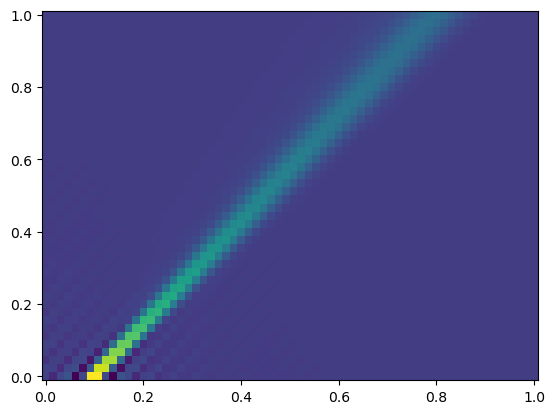

In [73]:
plt.pcolormesh(x_evals,t_evals,u_evals)

## Inverse

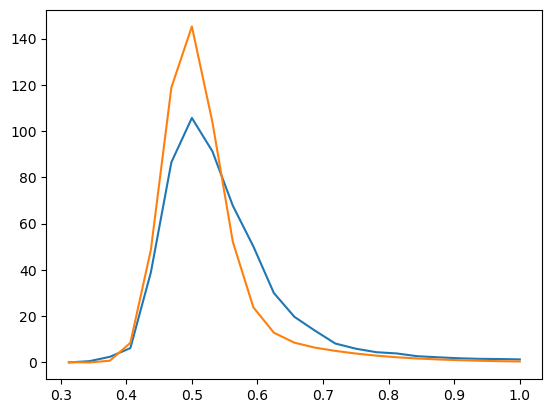

In [74]:
T_range = 2
### Breakthrough curve measured in Antietam Creek on 5/27/69
times_meas = np.array([2, 2.2, 2.4, 2.6, 2.8, 3, 3.2, 3.4, 3.6, 3.8, 4, 4.2, 4.4, 4.6, 4.8, 5, 5.2, 5.4, 5.6, 5.8, 6, 6.2, 6.4, 6.6, 6.8, 7, 7.2, 7.4, 7.6, 7.8, 8, 8.2, 8.4, 8.61, 8.8, 9, 9.2, 9.4, 9.6, 9.8, 10])
conc_meas = np.array([0, 0.55, 2.43, 6.2, 38.95, 86.53, 105.71, 91.3, 67.73, 50.17, 30.02, 19.74, 13.77, 8.17, 5.94, 4.43, 3.88, 2.69, 2.23, 1.81, 1.56, 1.47, 1.31, 1.12, 1.1, 0.9, 0.78, 0.69, 0.64, 0.62, 0.5, 0.53, 0.39, 0.37, 0.25, 0.11, 0.09, 0.02, 0, 0.02, 0])
ref_time = times_meas[np.argmax(conc_meas)]*T_range
i_data = np.argmin(np.abs(t_evals[np.argmax(u_evals,axis = 0)]-1/T_range))
ref_len = x_evals[i_data]- x_star 
data_times = (times_meas/ref_time)
M0_ref = np.trapezoid(conc_meas,data_times)*v_/M0_
data_vals = conc_meas[data_times<=1.0]
data_times = data_times[data_times<=1.0]
plt.plot(data_times,data_vals)
phi_data_eval = np.zeros((len(data_times),len(Xis)*n_states))
phi_data_eval[:,:len(Xis)] = phi_fun(x_evals[i_data],data_times[:,None,None],
                                     (np.arange(-extra_p,Nx+extra_p+1)/Nx),
                                     (np.arange(-extra_p,int(Nx*v_)+extra_p+1)/int(Nx*v_))[:,None],
                                     h_fac/Nx,
                                     h_fac/int(Nx*v_)).reshape((len(data_times),len(Xis)))
params = np.array([1,M0_ref,v_,D_,beta_*k_,k_])
A_par_dep_sum = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
b_par_dep_sum = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
A = A_par_dep_sum + A_par_indep + 10**-6*np.eye(2*len(Xis))
b = b_par_dep_sum + b_par_indep
u= np.linalg.solve(A,b)
plt.plot(data_times,np.sum(u*phi_data_eval,axis = 1))

In [75]:
np.random.seed(42)
x0s = np.zeros((5,5))
for i in range(len(x0s)):
    M0_ref_i = M0_ref*np.exp(np.random.uniform(-np.log(1.1),np.log(1.1)))
    v_i = v_*np.exp(np.random.uniform(-np.log(1.1),np.log(1.1)))
    D_i = D_*np.exp(np.random.uniform(-np.log(1.3),np.log(1.3)))
    beta_i = beta_*10**(np.random.uniform(-1,1))
    k_i = k_*10**(np.random.uniform(-1,1))
    x0s[i] = np.array([M0_ref_i,v_i,D_i,beta_i*k_i,k_i])

In [76]:
%%time
import time
maxiter = 20
params_hist_grad_hess = [[] for i in range(len(x0s))]
loss_hist_grad_hess = [[] for i in range(len(x0s))]
time_grad_hess = np.zeros(len(x0s))
fgH_lists = []
for i in range(len(x0s)):
    fgH_list = []
    def fgh(x):
        xt = tuple(x)  # makes it hashable
        if xt not in _cache:
            f, g, H = grad_hess_optimize_inverse(x, A_par_dep, A_par_indep, b_par_dep, b_par_indep,phi_data_eval,data_vals,epsilon = 10**-5)  # your function
            _cache[xt] = (f, g, H)
            fgH_list.append([f, g, H])
        return _cache[xt]
    
    def fun(x):
        params_hist_grad_hess[i].append(list(x))
        fun = fgh(x)[0]
        loss_hist_grad_hess[i].append(fun)
        print(format(fun,'.5f'), *[format(i,'.5f') for i in x])
        return fun
    
    def grad(x):
        return fgh(x)[1]
    
    def hess(x):
        return fgh(x)[2]
    # Cache dictionary
    _cache = {}
    start = time.time()
    
    # Run optimizer
    result_grad_hess = minimize(
        fun,
        x0s[i],
        method='trust-exact',  # must use trust-constr to handle constraints!
        jac=grad,
        hess=hess,
        # bounds=bounds,
        # constraints=[linear_constraint],
        options={'maxiter': 20}
    )
    
    print(result_grad_hess)
    
    time_grad_hess[i] = time.time()-start
    fgH_lists.append(fgH_list)

30472.28298 11.84782 0.76280 0.00090 0.16156 2.05134
374570345.57824 11.87329 -0.23857 -0.00398 0.05561 2.05006
217069.96460 11.84939 0.51184 0.00006 0.15688 2.05135
4719.86594 11.84775 0.70025 0.00108 0.16249 2.05137
835.20592 11.86120 0.67667 0.00128 0.28158 2.07793
414.42901 12.05010 0.67380 0.00145 0.37915 2.23240
344.97773 12.40331 0.67419 0.00153 0.44607 2.58045
296.33955 12.63719 0.67666 0.00147 0.54360 3.62138
239.69351 12.20754 0.68003 0.00139 0.58184 5.57477
157.04212 12.07630 0.68683 0.00121 0.82480 9.56630
102.64934 12.00896 0.69375 0.00109 1.15716 13.53261
70.90981 12.03121 0.70004 0.00100 1.51955 16.37053
52.13797 12.05866 0.70700 0.00090 1.94507 19.19137
41.80512 12.09213 0.71257 0.00083 2.32355 21.25578
37.20395 12.12328 0.71767 0.00077 2.68743 23.12112
35.67502 12.14561 0.72083 0.00074 2.92904 24.23344
35.39876 12.15847 0.72264 0.00072 3.06920 24.86410
35.38352 12.16184 0.72309 0.00072 3.10507 25.01891
35.38345 12.16209 0.72312 0.00072 3.10779 25.03070
35.38345 12.1620

In [77]:
%%time
maxiter = 38
params_hist_grad = [[] for i in range(len(x0s))]
loss_hist_grad = [[] for i in range(len(x0s))]
time_grad = np.zeros(len(x0s))
for i in range(len(x0s)):
    def fg(x):
        xt = tuple(x)  # makes it hashable
        if xt not in _cache:
            f, g = grad_optimize_inverse(x, A_par_dep, A_par_indep, b_par_dep, b_par_indep,phi_data_eval,data_vals,epsilon = 10**-4)  # your function
            _cache[xt] = (f, g)
        return _cache[xt]
    
    def fun(x):
        params_hist_grad[i].append(list(x))
        fun = fg(x)[0]
        loss_hist_grad[i].append(fun)
        print(format(fun,'.5f'), *[format(i,'.5f') for i in x])
        return fun
    
    def grad(x):
        return fg(x)[1]
    
    # Cache dictionary
    _cache = {}
    start = time.time()
    # Run optimizer
    result_grad = minimize(
        fun,
        x0s[i],
        method='L-BFGS-B',  # must use trust-constr to handle constraints!
        jac=grad,
        options={'maxiter': maxiter}
    )
    
    print(result_grad_hess)
    
    time_grad[i] =  time.time()-start

30390.68511 11.84782 0.76280 0.00090 0.16156 2.05134
37291.51953 11.84766 0.74173 1.00068 0.16253 2.05135
35895.97964 11.84777 0.75578 0.33397 0.16188 2.05134
30416.41348 11.84780 0.76046 0.11179 0.16166 2.05134
23051.50674 11.84781 0.76202 0.03791 0.16159 2.05134
22995.67551 11.84781 0.76200 0.03762 0.16159 2.05134
22768.25856 11.84782 0.76194 0.03645 0.16157 2.05134
21788.55897 11.84784 0.76169 0.03176 0.16150 2.05134
16247.14470 11.84791 0.76067 0.01304 0.16121 2.05136
103230808.51536 11.84820 0.75659 -0.06188 0.16004 2.05140
16246.73679 11.84791 0.76067 0.01304 0.16121 2.05136
16246.32888 11.84791 0.76067 0.01303 0.16121 2.05136
28396929.34059 11.84806 0.75863 -0.02442 0.16062 2.05138
16241.99790 11.84791 0.76066 0.01302 0.16121 2.05136
16237.32895 11.84791 0.76066 0.01301 0.16121 2.05136
23859018.23600 11.84798 0.75965 -0.00570 0.16091 2.05137
14249.01016 11.84793 0.76041 0.00836 0.16113 2.05136
14480.92896 11.84795 0.76011 0.00281 0.16105 2.05136
13171.64066 11.84794 0.76025 0.00

In [78]:
%%time
from scipy.optimize import minimize
params_hist_no_grad = [[] for i in range(len(x0s))]
loss_hist_no_grad = [[] for i in range(len(x0s))]
time_no_grad = np.zeros(len(x0s))
for i in range(len(x0s)):
    def fun(pars):
        params_hist_no_grad[i].append(list(pars))
        fun = no_grad_optimize_inverse(pars,A_par_dep, A_par_indep, b_par_dep, b_par_indep,phi_data_eval,data_vals, epsilon = 10**-5)
        loss_hist_no_grad[i].append(fun)
        print(format(fun,'.5f'), *[format(i,'.5f') for i in pars])
        return fun
    start = time.time()
    result_no_grad = minimize(fun, x0=x0s[i],method='Nelder-Mead',
                              options={'maxfev': 150})
    time_no_grad[i] =  time.time()-start

30472.28284 11.84782 0.76280 0.00090 0.16156 2.05134
32803.03901 12.44021 0.76280 0.00090 0.16156 2.05134
49297.67190 11.84782 0.80094 0.00090 0.16156 2.05134
29445.06150 11.84782 0.76280 0.00095 0.16156 2.05134
30286.49665 11.84782 0.76280 0.00090 0.16963 2.05134
30449.33208 11.84782 0.76280 0.00090 0.16156 2.15391
13629.34736 12.08477 0.72466 0.00092 0.16479 2.09237
4719.76120 12.20325 0.68652 0.00093 0.16640 2.11288
14742.96314 11.39760 0.73229 0.00093 0.16673 2.11698
11035.35143 11.80991 0.72008 0.00094 0.16879 2.14324
6150.42168 11.79474 0.70300 0.00096 0.17169 2.03640
3074.94391 11.77351 0.67907 0.00098 0.16443 2.13300
8082.89141 11.73635 0.63721 0.00102 0.16183 2.17383
6810.43530 11.74378 0.64558 0.00095 0.17366 2.16566
8710.56254 12.33248 0.64142 0.00098 0.17127 2.11949
14547.93053 12.12920 0.62215 0.00098 0.17019 2.08374
5030.93000 11.88973 0.69560 0.00095 0.16914 2.12836
11228.75561 11.42953 0.72249 0.00094 0.16687 2.11103
4474.75630 12.10674 0.66169 0.00097 0.17017 2.11738
1

In [79]:
loss_hist_no_grad_np = np.zeros((len(x0s),max([len(l) for l in loss_hist_no_grad]))) + np.nan
loss_hist_grad_np = np.zeros((len(x0s),max([len(l) for l in loss_hist_grad]))) + np.nan
loss_hist_grad_hess_np = np.zeros((len(x0s),max([len(l) for l in loss_hist_grad_hess]))) + np.nan
for i in range(len(x0s)):
    loss_hist_no_grad_np[i,:len(loss_hist_no_grad[i])] = loss_hist_no_grad[i]
    loss_hist_grad_np[i,:len(loss_hist_grad[i])] = loss_hist_grad[i]
    loss_hist_grad_hess_np[i,:len(loss_hist_grad_hess[i])] = loss_hist_grad_hess[i]

In [80]:

x0_median = np.argsort([l[0] for l in loss_hist_no_grad])[len(x0s)//2]
params = np.concatenate(([1],x0s[x0_median]))
A_par_dep_sum = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
b_par_dep_sum = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
A = A_par_dep_sum + A_par_indep + 10**-6*np.eye(2*len(Xis))
b = b_par_dep_sum + b_par_indep
u_x0= np.linalg.solve(A,b)

x0_median = np.argsort([l[-1] for l in loss_hist_no_grad])[len(x0s)//2]
params = np.concatenate(([1],params_hist_no_grad[x0_median][-1]))
print(params)
A_par_dep_sum = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
b_par_dep_sum = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
A = A_par_dep_sum + A_par_indep + 10**-6*np.eye(2*len(Xis))
b = b_par_dep_sum + b_par_indep
u_no_grad= np.linalg.solve(A,b)


x0_median = np.argsort([l[-1] for l in loss_hist_grad])[len(x0s)//2]
params = np.concatenate(([1],params_hist_grad[x0_median][-1]))
print(params)
A_par_dep_sum = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
b_par_dep_sum = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
A = A_par_dep_sum + A_par_indep + 10**-6*np.eye(2*len(Xis))
b = b_par_dep_sum + b_par_indep
u_grad= np.linalg.solve(A,b)


x0_median = np.argsort([l[-1] for l in loss_hist_grad_hess])[len(x0s)//2]
params = np.concatenate(([1],params_hist_grad_hess[x0_median][-1]))
print(params)
A_par_dep_sum = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
b_par_dep_sum = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0))
A = A_par_dep_sum + A_par_indep + 10**-6*np.eye(2*len(Xis))
b = b_par_dep_sum + b_par_indep
u_grad_hess= np.linalg.solve(A,b)


[1.00000000e+00 1.19297332e+01 6.70984181e-01 1.68694860e-03
 2.41256263e-01 1.32734698e+00]
[1.00000000e+00 1.21380185e+01 6.77162905e-01 1.48281645e-03
 4.21465280e-01 4.02995836e+00]
[1.00000000e+00 1.21620945e+01 7.23124643e-01 7.15588925e-04
 3.10780702e+00 2.50307534e+01]


In [81]:
import numpy as np

def ADEFO_sol(ts, xs, M0, v, D, beta_k, k):
    """
    Solves the advection-diffusion equation
    ts = Array. Times after release
    xs = Array. Distance from the point of release
    v = Float. Advection velocity
    D = Float. Diffusion coefficient
    """
    def sol_lap_space(s, x):
        U = M0/np.sqrt(v**2+4*D*s*(1+beta_k/(s+k)))*np.exp(v/(2*D)*x-np.sqrt(v**2+4*D*s*(1+beta_k/(s+k)))/(2*D)*np.abs(x))
        return U
    u = np.array([invlap(sol_lap_space, ts, [x]) for x in xs])
    return u

In [82]:
L = 2.574944
T_rescaling = (T_range*times_meas[np.argmax(conc_meas)])
L_rescaling = (L/ref_len)
ts_plot = np.linspace(times_meas[0],times_meas[len(data_times)],200)[1:]
btcs_lap = []
pars_dim_all = []

x0_median = np.argsort([l[0] for l in loss_hist_no_grad])[len(x0s)//2]
params = x0s[x0_median]
M0_dimensional = params[0]*L_rescaling
v_dimensional = params[1]/T_rescaling*L_rescaling
D_dimensional = params[2]/T_rescaling*L_rescaling**2
beta_k_dimensional = params[3]/T_rescaling
k_dimensional = params[4]/T_rescaling
pars_dim_x0 = [M0_dimensional,v_dimensional,D_dimensional,beta_k_dimensional,k_dimensional]
print(*[format(p,'.5f') for p in pars_dim_x0])
btc_lap_x0 = ADEFO_sol(ts_plot,[L],*pars_dim_x0)[0]

for loss_hist,params_hist in zip([loss_hist_no_grad,loss_hist_grad,loss_hist_grad_hess],[params_hist_no_grad,params_hist_grad,params_hist_grad_hess]):
    x0_median = np.argsort([l[-1] for l in loss_hist])[len(x0s)//2]
    params = params_hist[x0_median][-1]
    M0_dimensional = params[0]*L_rescaling
    v_dimensional = params[1]/T_rescaling*L_rescaling
    D_dimensional = params[2]/T_rescaling*L_rescaling**2
    beta_k_dimensional = params[3]/T_rescaling
    k_dimensional = params[4]/T_rescaling
    pars_dim = [M0_dimensional,v_dimensional,D_dimensional,beta_k_dimensional,k_dimensional]
    pars_dim_all.append(pars_dim)
    print(*[format(p,'.5f') for p in pars_dim])
    btc_lap = ADEFO_sol(ts_plot,[L],*pars_dim)[0]
    btcs_lap.append(btc_lap)
btc_lap_no_grad, btc_lap_grad, btc_lap_grad_hess = btcs_lap
pars_dim_no_grad, pars_dim_grad, pars_dim_grad_hess = pars_dim_all

92.21106 0.75958 0.00620 0.03449 1.27632
88.74203 0.77989 0.01459 0.03770 0.20740
90.29141 0.78707 0.01282 0.06585 0.62968
90.47050 0.84049 0.00619 0.48559 3.91106


13.712750311123578


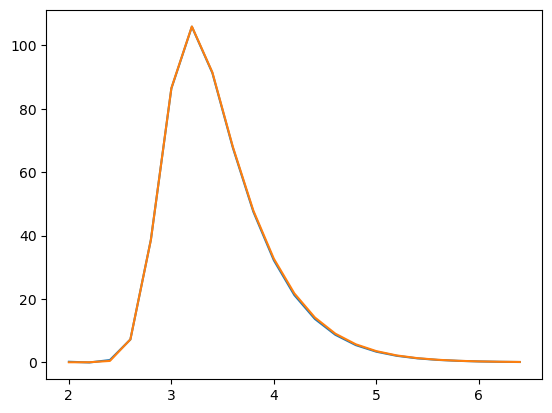

In [83]:
inverse_sol, recons_sol = np.sum(u_grad_hess*phi_data_eval,axis = 1),ADEFO_sol(data_times*ref_time,[L],*pars_dim_grad_hess)[0]
plt.plot(data_times*ref_time,inverse_sol)
plt.plot(data_times*ref_time,recons_sol)
print(np.sqrt(np.sum((ADEFO_sol(data_times*ref_time,[L],*pars_dim)[0]-np.sum(u*phi_data_eval,axis = 1))**2)/len(data_times)))

In [84]:
np.sqrt(np.mean((recons_sol-inverse_sol)**2)),np.sqrt(np.mean((recons_sol-data_vals)**2)),np.sqrt(np.mean((inverse_sol-data_vals)**2))

(np.float64(0.24656835658691262),
 np.float64(1.2776667474387813),
 np.float64(1.2286466022582019))

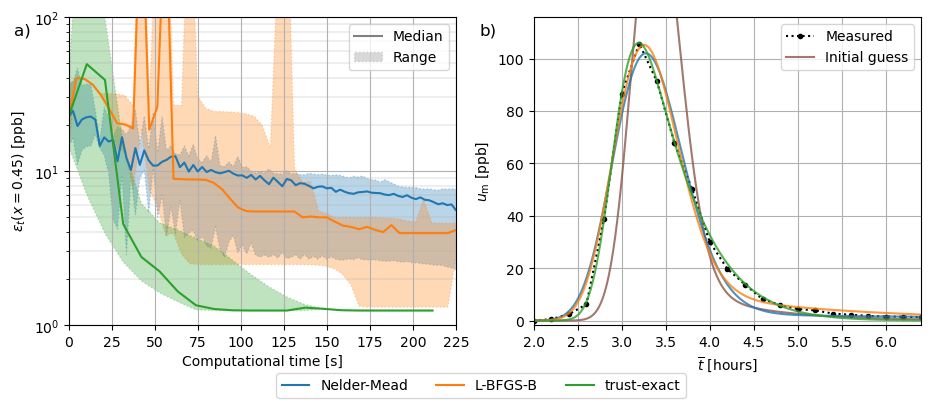

In [85]:
fig,axes  = plt.subplots(ncols = 2,figsize=(11, 4))

axes[0].semilogy([0,0],[10,10], c = 'gray', label = 'Median')
axes[0].fill_between([0,0],[10,10],[10,10], color = 'gray',linestyle = 'dotted', alpha = 0.3, label = 'Range')

axes[0].semilogy(np.linspace(0,np.mean(time_no_grad),loss_hist_no_grad_np.shape[1]),np.sqrt(np.nanmedian(loss_hist_no_grad_np,axis = 0)/len(data_vals)), c = 'tab:blue', label = 'Nelder-Mead')
axes[0].semilogy(np.linspace(0,np.mean(time_grad),loss_hist_grad_np.shape[1]),np.sqrt(np.nanmedian(loss_hist_grad_np,axis = 0)/len(data_vals)), c = 'tab:orange', label = 'L-BFGS-B')
axes[0].semilogy(np.linspace(0,np.mean(time_grad_hess),loss_hist_grad_hess_np.shape[1]),np.sqrt(np.nanmedian(loss_hist_grad_hess_np,axis = 0)/len(data_vals)), c = 'tab:green', label = 'trust-exact')


axes[0].fill_between(np.linspace(0,np.mean(time_no_grad),loss_hist_no_grad_np.shape[1]),
                 np.sqrt(np.nanmin(loss_hist_no_grad_np,axis = 0)/len(data_vals)), 
                 np.sqrt(np.nanmax(loss_hist_no_grad_np,axis = 0)/len(data_vals)), color = 'tab:blue',linestyle = 'dotted', alpha = 0.3)
axes[0].fill_between(np.linspace(0,np.mean(time_grad),loss_hist_grad_np.shape[1]),
                 np.sqrt(np.nanmin(loss_hist_grad_np,axis = 0)/len(data_vals)),
                 np.sqrt(np.nanmax(loss_hist_grad_np,axis = 0)/len(data_vals)), color = 'tab:orange',linestyle = 'dotted', alpha = 0.3)
axes[0].fill_between(np.linspace(0,np.mean(time_grad_hess),loss_hist_grad_hess_np.shape[1]),
                 np.sqrt(np.nanmin(loss_hist_grad_hess_np,axis = 0)/len(data_vals)),
                 np.sqrt(np.nanmax(loss_hist_grad_hess_np,axis = 0)/len(data_vals)), color = 'tab:green',linestyle = 'dotted', alpha = 0.3)

axes[0].set_ylim(1,100)
axes[0].grid()
axes[0].grid(which = 'minor',linewidth = 0.3)
axes[0].set_xlabel(r'Computational time [s]')
axes[0].set_ylabel(r'$\varepsilon_{t}(x=0.45)$ [ppb]')
axes[0].set_xlim(0,225)


axes[1].plot(times_meas[:len(data_times)],data_vals, c= 'k' , linestyle = 'dotted', marker = 'o', markersize = 3, label = 'Measured')
axes[1].plot(ts_plot, btc_lap_x0, c = 'tab:brown',alpha = 0.8, label = 'Initial guess')
axes[1].plot(ts_plot, btc_lap_no_grad,alpha = 0.8)
axes[1].plot(ts_plot, btc_lap_grad,alpha = 0.8)
axes[1].plot(ts_plot, btc_lap_grad_hess,alpha = 0.8)
axes[1].grid()
axes[1].set_xlabel(r'$\overline{t}$ [hours]')
axes[1].set_ylabel(r'$u_{\text{m}}$ [ppb]')
axes[1].set_xlim(np.min(times_meas[:len(data_times)]),np.max(times_meas[:len(data_times)]))
axes[1].set_ylim(*(np.max(btc_lap_x0)*np.array([-0.01,0.7])))
axes[1].legend()



plot_labels = ['a)', 'b)']

for ax, label in zip(axes.flat, plot_labels):
    ax.text(
        -0.14, 0.98, label,
        transform=ax.transAxes,
        fontsize=12,
        va='top', ha='left'
    )

handles, labels = axes[0].get_legend_handles_labels()

axes[0].legend(handles[:2], labels[:2])

fig.legend(handles[2:], labels[2:], 
           loc='lower center',       # Center the legend horizontally
           bbox_to_anchor=(0.5, -0.09), # Position the legend below the subplots
           ncol=3)

In [129]:
H_scaled = np.diag(np.mean(params_hist_grad_hess[-1],axis = 0)) @ fgH_lists[0][-1][-1] @ np.diag(np.mean(params_hist_grad_hess[-1],axis = 0))

# Enforce symmetry against minor numerical errors.
H_scaled = 0.5 * (H_scaled + H_scaled.T)
eigenvalues, eigenvectors = np.linalg.eig(H_scaled)

# Print Eigenvalues in LaTeX
print(r"\begin{bmatrix}" + " & ".join(f"{val:.4g}" for val in eigenvalues) + r"\end{bmatrix}")

# Print Eigenvectors in LaTeX
print(r"\begin{bmatrix}")
for row in eigenvectors:
    print(" & ".join(f"{val:.4f}" for val in row) + r" \\")
print(r"\end{bmatrix}")

\begin{bmatrix}2.884e+06 & 8.167e+04 & 7796 & 1676 & 45.19\end{bmatrix}
\begin{bmatrix}
-0.0109 & 0.9453 & -0.3209 & 0.0558 & 0.0138 \\
0.9988 & -0.0014 & -0.0342 & 0.0140 & 0.0324 \\
0.0003 & -0.1438 & -0.5678 & -0.7574 & -0.2885 \\
-0.0454 & -0.1799 & -0.4799 & 0.0682 & 0.8548 \\
0.0155 & 0.2310 & 0.5858 & -0.6468 & 0.4300 \\
\end{bmatrix}


# Problem 4

In [87]:
from scipy import special
def h_analyt(x_, t_, k_, Q_, x_star_):
    ns=np.arange(-10,11)
    total=1
    for n in ns:
        total-=(Q_/(2*k_)*abs(x_-(2*n+x_star_))*special.erfc(abs(x_-(2*n+x_star_))/(4*k_*t_)**(1/2))
                -Q_*(t_/(k_*np.pi))**(1/2)*np.exp(-(x_-(2*n+x_star_))**(2)/(4*k_*t_))
                -Q_/(2*k_)*abs(x_-(2*n-x_star_))*special.erfc(abs(x_-(2*n-x_star_))/(4*k_*t_)**(1/2))
                +Q_*(t_/(k_*np.pi))**(1/2)*np.exp(-(x_-(2*n-x_star_))**(2)/(4*k_*t_))
               )
    return total

In [88]:
# ============================================================
# Fixed parameters
# ============================================================

k, Q = 0.1, 1.0
x_star = 0.5
col_fac = 1.3

data_x = np.linspace(0, 1, 51)
data_t = np.ones_like(data_x)

PDE_funcs = [phi_t_fun,lambda x, t, x_i, t_i, h_x, h_t:-phi_xx_fun(x, t, x_i, t_i, h_x, h_t)]
R_funcs_rest = [lambda x, t, x_i, t_i, h_x, h_t: R_IC_dirich_fun(x, t, x_i, t_i, h_x, h_t, 0.0),
                lambda x, t, x_i, t_i, h_x, h_t: R_BC_dirich_fun(x, t, x_i, t_i, h_x, h_t, 0.0),
                lambda x, t, x_i, t_i, h_x, h_t: R_BC_dirich_fun(x, t, x_i, t_i, h_x, h_t, 1.0)]
funcs_b = [1.0,1.0,1.0,1.0]
xt_stars = [[x_star,None],None,None,None]

Nx_eval, Nt_eval = 200, 200
x_evals,t_evals = np.linspace(0,1,Nx_eval),np.linspace(0,1,Nt_eval)
u_ref = h_analyt(*np.meshgrid(x_evals,t_evals ), k, Q, x_star)

In [89]:
from skopt import gp_minimize
from skopt.space import Integer, Real
from skopt.utils import use_named_args

# ============================================================
# Evaluation grid and analytical solution
# ============================================================

Nx_eval, Nt_eval = 200, 200

x_evals = np.linspace(0, 1, Nx_eval)
t_evals = np.linspace(0, 1, Nt_eval)

X_eval, T_eval = np.meshgrid(x_evals, t_evals)

u_ref = h_analyt(X_eval, T_eval, k, Q, x_star)

# ============================================================
# Gaussian-process optimization space
# ============================================================

space = [Integer(4000, 6000, name="N_params_approx"),
    Real(-0.5, 0.5, name="t_x_log2_ratio"),
    Real(1.3, 1.7, name="h_fac"),
    Integer(1 ,4 , name="extra_p"),
    Real(-6, -3, name="log_reg")]


@use_named_args(space)
def objective(N_params_approx, t_x_log2_ratio, h_fac, extra_p, log_reg):

    t_x_ratio = 2**t_x_log2_ratio
    
    Nx = int(np.roots([t_x_ratio,2 * extra_p * (1+t_x_ratio) ,  4 * extra_p**2 -N_params_approx ])[1])
    Nt = int(Nx*t_x_ratio)
    
    N_parameters = (Nx + 2 * extra_p) * (Nt + 2 * extra_p)


    A_PDE, phi_data_eval, A_rest, b_PDE, b_rest = compute_matrices_for_inverse(x_star,Nx,Nt,h_fac,extra_p,col_fac,data_x,data_t,
            PDE_funcs,R_funcs_rest,funcs_b,xt_stars)

    
    A = np.sum((np.array([1,k])*np.array([1,k])[:,None])[:,:,None,None]*A_PDE,axis = (0,1))+A_rest+np.ones_like(A_rest)*10**log_reg
    b = np.sum(np.array([1,k])[:,None]*b_PDE,axis = (0))+b_rest
    u= np.linalg.solve(A,b)
    
    u_eval = np.sum(np.sum(u.reshape((Nt+extra_p*2+1,Nx+extra_p*2+1))*phi_fun(x_evals[None,:,None,None],
                                         t_evals[:,None,None,None],
                                         (np.arange(-extra_p,Nx+extra_p+1)/Nx),
                                         (np.arange(-extra_p,Nt+extra_p+1)/Nt)[:,None],
                                         h_fac/Nx,
                                         h_fac/Nt),axis = -1),axis = -1)


    error_field = u_eval - u_ref

    error_aq = np.sqrt(np.mean(error_field**2))

    print(f"Nx={Nx:2d}, Nt={Nt:2d}, "
        f"h={h_fac:.3f}, p={extra_p}, "
        f"log10(eps)={log_reg:.3f}, "
        f"Npar={N_parameters:4d}, "
        f"RMSE={error_aq:.6e}")

    return error_aq

In [90]:
%%time

result = gp_minimize(
    objective,
    space,
    n_calls=100,
    n_initial_points=8,
    acq_func="EI",
    random_state=1,
    verbose=False
)

0.5 59 79 1.3512497791717428 4
Nx=59, Nt=79, h=1.351, p=4, log10(eps)=-5.292, Npar=5829, RMSE=9.111570e+01
0.5 63 58 1.567898414721392 4
Nx=63, Nt=58, h=1.568, p=4, log10(eps)=-3.461, Npar=4686, RMSE=1.080486e+02
0.5 63 64 1.4773811575118228 2
Nx=63, Nt=64, h=1.477, p=2, log10(eps)=-4.397, Npar=4556, RMSE=1.413256e-02
0.5 69 66 1.4722794268738835 4
Nx=69, Nt=66, h=1.472, p=4, log10(eps)=-3.665, Npar=5698, RMSE=2.541100e+01
0.5 60 74 1.3371203234562952 3
Nx=60, Nt=74, h=1.337, p=3, log10(eps)=-3.405, Npar=5280, RMSE=1.572228e-01
0.5 65 81 1.409219989686699 1
Nx=65, Nt=81, h=1.409, p=1, log10(eps)=-3.988, Npar=5561, RMSE=1.328970e-01
0.5 64 72 1.4647151515876213 2
Nx=64, Nt=72, h=1.465, p=2, log10(eps)=-5.131, Npar=5168, RMSE=1.432747e-02
0.5 57 69 1.4650155366012105 1
Nx=57, Nt=69, h=1.465, p=1, log10(eps)=-4.128, Npar=4189, RMSE=7.769590e-02
0.5 61 53 1.4837611891649765 3
Nx=61, Nt=53, h=1.484, p=3, log10(eps)=-4.502, Npar=3953, RMSE=8.488906e+00
0.5 66 85 1.3709598306069193 1
Nx=66, N

C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(4000), 0.5, 1.7, np.int64(3), -3.0] before, using random point [np.int64(5421), -0.06001228458553931, 1.5757090119409047, np.int64(4), -5.932576979386596]
  warnings.warn(


0.5 67 64 1.5757090119409047 4
Nx=67, Nt=64, h=1.576, p=4, log10(eps)=-5.933, Npar=5400, RMSE=2.548290e+01
0.5 67 47 1.3 3
Nx=67, Nt=47, h=1.300, p=3, log10(eps)=-3.000, Npar=3869, RMSE=1.172599e-01
0.5 65 67 1.7 1
Nx=65, Nt=67, h=1.700, p=1, log10(eps)=-6.000, Npar=4623, RMSE=2.767228e-02
0.5 59 83 1.4084352959979036 3
Nx=59, Nt=83, h=1.408, p=3, log10(eps)=-4.963, Npar=5785, RMSE=4.419606e-02
0.5 63 69 1.5423310400890542 1
Nx=63, Nt=69, h=1.542, p=1, log10(eps)=-6.000, Npar=4615, RMSE=2.602991e-02


C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(4000), -0.5, 1.3, np.int64(3), -3.0] before, using random point [np.int64(5174), 0.16552760608259542, 1.390852285805503, np.int64(3), -3.337997545298411]
  warnings.warn(


0.5 62 69 1.390852285805503 3
Nx=62, Nt=69, h=1.391, p=3, log10(eps)=-3.338, Npar=5100, RMSE=6.418702e-01
0.5 83 64 1.6123088333760358 2
Nx=83, Nt=64, h=1.612, p=2, log10(eps)=-5.655, Npar=5916, RMSE=7.850813e-03
0.5 66 56 1.3 1
Nx=66, Nt=56, h=1.300, p=1, log10(eps)=-5.710, Npar=3944, RMSE=2.118759e-01
0.5 59 83 1.418956408603494 3
Nx=59, Nt=83, h=1.419, p=3, log10(eps)=-5.540, Npar=5785, RMSE=1.503643e-01


C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(4000), -0.5, 1.3, np.int64(3), -3.0] before, using random point [np.int64(4985), 0.3582633465565219, 1.3140576675867015, np.int64(3), -5.254102621755345]
  warnings.warn(


0.5 57 73 1.3140576675867015 3
Nx=57, Nt=73, h=1.314, p=3, log10(eps)=-5.254, Npar=4977, RMSE=2.218066e-01
0.5 55 75 1.476074673404995 1
Nx=55, Nt=75, h=1.476, p=1, log10(eps)=-6.000, Npar=4389, RMSE=3.466513e-02
0.5 67 47 1.3 3
Nx=67, Nt=47, h=1.300, p=3, log10(eps)=-3.500, Npar=3869, RMSE=7.798539e-01
0.5 69 64 1.4927005997748555 2
Nx=69, Nt=64, h=1.493, p=2, log10(eps)=-5.710, Npar=4964, RMSE=3.622122e-03
0.5 72 50 1.6459862361767033 1
Nx=72, Nt=50, h=1.646, p=1, log10(eps)=-6.000, Npar=3848, RMSE=2.957676e-02
0.5 72 51 1.7 1
Nx=72, Nt=51, h=1.700, p=1, log10(eps)=-6.000, Npar=3922, RMSE=2.478494e-02
0.5 51 72 1.637683534978984 1
Nx=51, Nt=72, h=1.638, p=1, log10(eps)=-6.000, Npar=3922, RMSE=1.613834e-02
0.5 51 72 1.6655777222413044 1
Nx=51, Nt=72, h=1.666, p=1, log10(eps)=-4.451, Npar=3922, RMSE=1.719824e-02
0.5 79 56 1.4403955989954005 2
Nx=79, Nt=56, h=1.440, p=2, log10(eps)=-6.000, Npar=4980, RMSE=1.599073e-02
0.5 67 47 1.6418753537016748 3
Nx=67, Nt=47, h=1.642, p=3, log10(eps)

In [91]:
%%time
print(result.x,result.fun)
N_params_approx, t_x_log2_ratio, h_fac, extra_p, log_reg = result.x
t_x_ratio = 2**t_x_log2_ratio

# Nx = Nt = 80
# h_fac = 1.7
# extra_p = 3
# log_reg = -4

Nx = int(np.roots([t_x_ratio,2 * extra_p * (1+t_x_ratio) ,  4 * extra_p**2 -N_params_approx ])[1])
Nt = int(Nx*t_x_ratio)

N_parameters = (Nx + 2 * extra_p) * (Nt + 2 * extra_p)

A_PDE,phi_data_eval,A_rest,b_PDE,b_rest = compute_matrices_for_inverse(x_star,Nx,Nt,h_fac,extra_p,col_fac,
                                 data_x,data_t,
                                 PDE_funcs,R_funcs_rest,
                                 funcs_b,xt_stars)

A = np.sum((np.array([1,k])*np.array([1,k])[:,None])[:,:,None,None]*A_PDE,axis = (0,1))+A_rest+np.ones_like(A_rest)**10**log_reg
b = np.sum(np.array([1,k])[:,None]*b_PDE,axis = (0))+b_rest
u= np.linalg.solve(A,b)

u_eval = np.sum(np.sum(u.reshape((Nt+extra_p*2+1,Nx+extra_p*2+1))*phi_fun(x_evals[None,:,None,None],
                                     t_evals[:,None,None,None],
                                     (np.arange(-extra_p,Nx+extra_p+1)/Nx),
                                     (np.arange(-extra_p,Nt+extra_p+1)/Nt)[:,None],
                                     h_fac/Nx,
                                     h_fac/Nt),axis = -1),axis = -1)



error_field = u_eval-u_ref
error_aq = np.sqrt(np.sum(error_field**2)/(error_field.size))

[np.int64(5066), -0.09340324700214714, 1.4927005997748555, np.int64(2), -5.7101020391386355] 0.0036221215187491602
0.5 69 64 1.4927005997748555 2
CPU times: total: 1min 14s
Wall time: 19.2 s


In [92]:
error_aq

np.float64(0.005167846533640276)

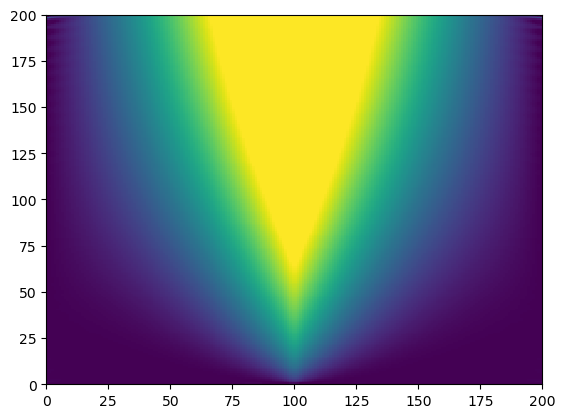

In [93]:
plt.pcolormesh(u_eval,vmin = 1,vmax= 2)

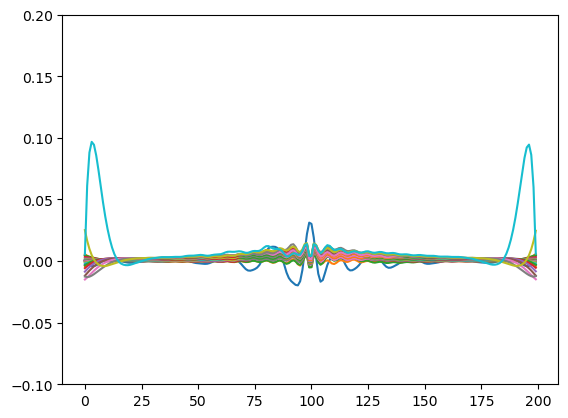

In [94]:
for i in np.linspace(0,Nt_eval-1,30).astype(int):
    plt.plot(u_eval[i]-u_ref[i])
plt.ylim(-0.1,0.2)
np.save('RBF_local_forcing.npy',u_eval)

## Inverse

In [95]:
A_par_dep = A_PDE
b_par_dep = np.zeros((A_PDE.shape[:-1]))
b_par_dep[0] = b_PDE
A_par_indep = A_rest
b_par_indep = b_rest

In [96]:
np.random.seed(0)
x0s =  [[k*2**np.random.uniform(-1,1)] for i in range(30)]
data_vals_all = h_analyt(data_x,data_t, k, Q, x_star)*(np.random.uniform(0.9,1.1,size = (30,len(data_x))))

In [97]:
np.mean(2**np.random.uniform(-0.05,0.05,size = (30,len(data_x)))[0]>1)

np.float64(0.5686274509803921)

In [98]:
data_vals_no_noise = h_analyt(data_x,data_t, k, Q, x_star)

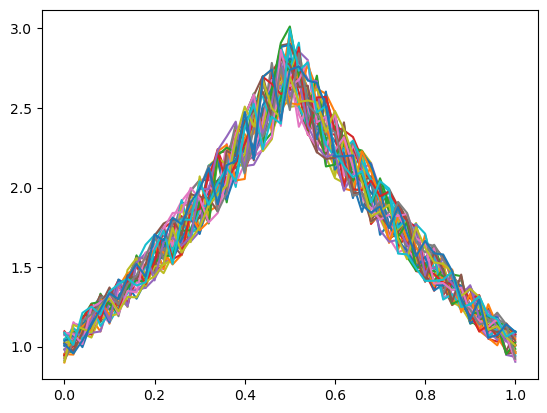

In [99]:
A = np.sum((np.array([1,k])*np.array([1,k])[:,None])[:,:,None,None]*A_PDE,axis = (0,1))+A_rest
b = np.sum(np.array([1,k])[:,None]*b_PDE,axis = (0))+b_rest
u= np.linalg.solve(A,b)
u_loc = np.sum(u * phi_data_eval, axis=-1)
plt.plot(data_x,u_loc)
for data_vals in data_vals_all:
    plt.plot(data_x,data_vals)

In [100]:
%%time
results_grad_hess = []
for x0,data_vals in zip(x0s,data_vals_all):
    
    def fgh(x):
        xt = tuple(x)  # makes it hashable
        if xt not in _cache:
            f, g, H = grad_hess_optimize_inverse(x,A_par_dep,A_par_indep,b_par_dep,b_par_indep,phi_data_eval,data_vals,epsilon = 10**-5)  # your function
            _cache[xt] = (f, g, H)
        return _cache[xt]
    
    def fun(x):
        return fgh(x)[0]
    
    def grad(x):
        return fgh(x)[1]
    
    def hess(x):
        return fgh(x)[2]
    # Cache dictionary
    _cache = {}
    result_grad_hess = minimize(fun, x0, method='trust-exact', jac=grad, hess=hess)
    print(format(result_grad_hess.fun,'.5%'),
      *[format(abs(i),'.5%') for i in result_grad_hess.x/np.array([k])-1],
      format(np.linalg.norm(h_analyt(data_x,data_t,*result_grad_hess.x,Q,x_star)-data_vals)/np.sqrt(len(data_vals)),'.5%'))
    results_grad_hess.append(result_grad_hess)

48.30545% 11.04837% 9.75844%
49.25135% 3.21943% 9.82105%
62.61355% 2.69462% 11.07535%
57.26654% 3.15296% 10.54223%
65.06564% 0.73657% 11.33957%
60.41345% 11.63368% 10.81328%
48.17257% 3.27566% 9.64398%
55.90938% 15.51363% 10.54424%
62.50030% 1.14973% 11.10170%
47.47490% 1.99638% 9.56424%
62.51396% 9.69568% 10.97153%
52.48828% 0.08023% 10.16205%
44.17175% 2.39604% 9.33173%
58.01982% 0.53868% 10.67538%
59.49687% 5.24321% 10.75476%
54.89691% 6.52913% 10.38889%
46.67749% 0.01355% 9.62625%
57.21945% 1.79843% 10.55343%
55.94792% 3.43136% 10.43028%
59.26536% 3.97973% 10.67835%
72.14306% 3.30800% 11.96601%
67.43764% 4.37892% 11.41633%
52.95782% 4.05762% 10.22682%
65.59762% 6.59270% 11.38303%
59.97752% 0.02310% 10.86471%
65.41976% 1.85168% 11.40123%
54.25544% 4.44467% 10.36910%
54.15662% 1.44719% 10.32537%
64.36371% 0.91204% 11.20730%
56.88321% 5.49406% 10.63441%
CPU times: total: 20min 12s
Wall time: 8min 55s


In [102]:
recons_x0_vals = [h_analyt(data_x,data_t,x0[0],Q,x_star) for x0 in x0s]

In [103]:
%%time
recons_vals = [h_analyt(data_x,data_t,*res.x,Q,x_star) for res in results_grad_hess]
inverse_vals = [np.sum(np.linalg.solve(
    np.sum((np.array([1,res.x[0]])*np.array([1,res.x[0]])[:,None])[:,:,None,None]*A_PDE,axis = (0,1))
    +A_rest,np.sum(np.array([1,res.x[0]])[:,None]*b_PDE,axis = (0))+b_rest)*phi_data_eval,axis = 1)  for res in results_grad_hess]

CPU times: total: 1min 32s
Wall time: 1min 36s


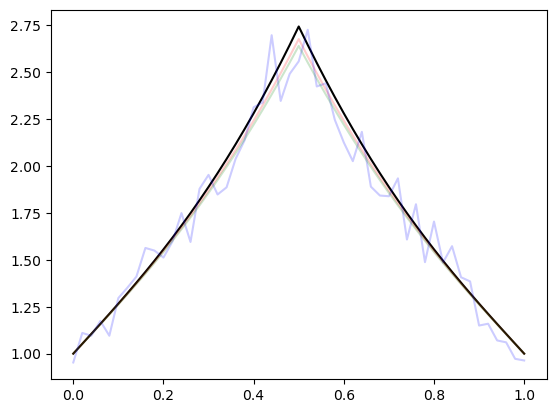

In [104]:
plt.plot(data_x,data_vals_no_noise, c = 'k')
for i in range(1):
    plt.plot(data_x,recons_x0_vals[i], c = 'r', alpha = 0.2)
    plt.plot(data_x,data_vals_all[i],c = 'b', alpha = 0.2)
    plt.plot(data_x,recons_vals[i],c = 'g', alpha = 0.2)

In [105]:
all_vals = [[data_vals_no_noise  for res in results_grad_hess],
            data_vals_all,
            recons_x0_vals,
            inverse_vals,
            recons_vals]

In [106]:
%%time
np.set_printoptions(formatter={'float': lambda x: f"{x:.3f}"})
RMSDs_mat = []
for val_i,name_i in zip(all_vals,['Noiseless','Noisy', 'Recons. init','Inverse','Reconstruct']):
    RMSDs = [[np.sqrt(np.sum((val_i[i]-val_j[i])**2)/len(data_vals_no_noise)) for i in range(len(x0s))] for val_j in all_vals]
    RMSDs_mat.append(RMSDs)
    print(name_i,*np.percentile(RMSDs,[10,50,90],axis = 1).T)
np.set_printoptions(formatter=None)

Noiseless [0.000 0.000 0.000] [0.098 0.108 0.116] [0.025 0.162 0.260] [0.005 0.015 0.039] [0.002 0.013 0.041]
Noisy [0.098 0.108 0.116] [0.000 0.000 0.000] [0.102 0.193 0.277] [0.097 0.106 0.113] [0.096 0.106 0.114]
Recons. init [0.025 0.162 0.260] [0.102 0.193 0.277] [0.000 0.000 0.000] [0.018 0.158 0.259] [0.016 0.153 0.255]
Inverse [0.005 0.015 0.039] [0.097 0.106 0.113] [0.018 0.158 0.259] [0.000 0.000 0.000] [0.007 0.007 0.007]
Reconstruct [0.002 0.013 0.041] [0.096 0.106 0.114] [0.016 0.153 0.255] [0.007 0.007 0.007] [0.000 0.000 0.000]
CPU times: total: 15.6 ms
Wall time: 10.6 ms


In [107]:
np.set_printoptions(formatter={'float': lambda x: f"{x*100:.3f}%"})
print(*np.percentile([np.abs(res.x/np.array([k])-1) for res in results_grad_hess],[10,50,90],axis = 0).T,
         *np.percentile([np.abs(x0/np.array([k])-1) for x0 in x0s],[10,50,90],axis = 0).T)
np.set_printoptions(formatter=None)

[0.493% 3.248% 9.831%] [6.298% 40.049% 80.883%]
